# CFDE Multi-Dataset Crossing Reports
This notebook aims to construct short articles about significant crossings from the CFDE Multi-Dataset Crossing project by combining information about the datasets, intersecting genes, and enrichment analysis results.

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from openai import OpenAI
import os
import shutil
import pandas as pd
import requests
from tqdm import tqdm
from venn import venn
import jinja2
import subprocess

from utils import format_deepdive, load_gmt, load_rummageo_gmt

In [2]:
def clean_term(term:str)->str:
    words = term.split(' ')
    for i in range(len(words)):
        words[i] = words[i].lower() if i > 0 else words[i]
    return ' '.join(words)

In [3]:
ENRICHR_URL = 'https://maayanlab.cloud/Enrichr'
enrichment_result_columns = ['Rank', 'Term name', 'P-value', 'Odds ratio', 'Combined score', 'Overlapping genes', 'Adjusted p-value', 'Old p-value', 'Old adjusted p-value']

def enrich(gene_set_id: str, library:str):
    response = requests.get(
        url=f"{ENRICHR_URL}/enrich?userListId={gene_set_id}&backgroundType={library}"
    )
    if not response.ok:
        print(response.text)

    return pd.DataFrame(json.loads(response.text)[library], columns=enrichment_result_columns).set_index('Rank')

In [4]:
def sanitize(text: str) -> str:
    text = text.replace("‑","-").replace("–","-")
    text = text.replace(" "," ").replace(" "," ").replace("↔"," ")
    text = text.replace("⁺","+")
    text = text.replace("_","\\_")
    text = text.replace("α","$\\alpha$")
    text = text.replace("β","$\\beta$")
    return text

In [5]:
client = OpenAI(base_url=os.getenv("LITELLM_ADDRESS"),api_key=os.getenv('LITELLM_API_KEY'))
model = "gpt-oss-120b"

#client = OpenAI()
#model = 'gpt-5-mini'

In [6]:
def ast_to_latex(node: dict) -> str:
    def sanitize(text: str) -> str:
        text = text.replace("‑","-").replace("–","-")
        text = text.replace(" "," ").replace(" "," ").replace("↔"," ")
        text = text.replace("⁺","+")
        text = text.replace("α","$\\alpha$")
        text = text.replace("β","$\\beta$")
        return text

    def process_node(node: dict) -> str:
        ntype = node.get('type')

        if ntype == 'root':
            return '\n\n'.join(process_node(child) for child in node.get('children', []))

        elif ntype == 'p':
            result = ''
            i = 0
            children = node.get('children', [])
            while i < len(children):
                child = children[i]
                if child['type'] == 't':
                    text = child['text']
                    # Collect all consecutive fg nodes that follow this text node
                    j = i + 1
                    while j < len(children) and children[j]['type'] == 'fg':
                        j += 1
                    if j > i + 1:
                        all_refs = []
                        for fg_node in children[i + 1:j]:
                            all_refs += [f['ref'] for f in fg_node.get('children', []) if f['type'] == 'fg_f']
                        cite_str = ','.join(all_refs)
                        stripped = text.rstrip()
                        punct = stripped[-1] if stripped and stripped[-1] in '.!?' else ''
                        body = stripped[:-1] if punct else stripped
                        result += f'{body} \\autocite{{{cite_str}}}{punct}'
                        i = j
                    else:
                        result += text
                        i += 1
                elif child['type'] == 'fg':
                    # Collect this and any immediately following fg nodes
                    j = i
                    all_refs = []
                    while j < len(children) and children[j]['type'] == 'fg':
                        all_refs += [f['ref'] for f in children[j].get('children', []) if f['type'] == 'fg_f']
                        j += 1
                    cite_str = ','.join(all_refs)
                    result += f' \\autocite{{{cite_str}}}'
                    i = j
                else:
                    i += 1
            return result

        return ''

    return sanitize(process_node(node))

In [7]:
def get_gene_bibtex_from_doi(key, doi):
    url = f'http://dx.doi.org/{doi}'

    res = requests.get(url, headers={'Accept':'application/x-bibtex'})

    if not res.ok:
        return f"Error fetching DOI {doi}: {res.status_code} {res.text}"
    res.encoding = 'utf-8'
    ref = res.text
    c = ref.split(",")
    c[0] = "@misc{"+key
    return ",".join(c)

In [8]:
def get_bibtex_from_doi(doi):
    url = f'http://dx.doi.org/{doi}'

    res = requests.get(url, headers={'Accept':'application/x-bibtex'})

    if not res.ok:
        return f"Error fetching DOI {doi}: {res.status_code} {res.text}"
    res.encoding = 'utf-8'
    return res.text

In [9]:
def truncate(text:str, length:int=70):
    if len(text) >= length:
        text = f'{text[:length-3]}...'
    return text

In [10]:
deepdive_summaries = pd.read_pickle('deepdive_gpt4o_markdown_descriptions.pkl')
ast_example = deepdive_summaries['A1BG']

In [11]:
def rummageo_to_pmid(rummageo_term):
  gse = rummageo_term.split(' ')[0]
  query = """
  query GSEPmid {
    geneSetTermSearch(terms: "%s", first: 1) {
      edges {
        node {
          id
          gse
          pmid
        }
      }
    }
  }
  """ % gse

  study_pmid = requests.post(
      url="https://rummageo.com/graphql",
      data={"query":query}
  )

  if study_pmid.ok:
    edge = study_pmid.json()["data"]['geneSetTermSearch']["edges"][0]["node"]
    return edge["pmid"] if edge["gse"]==gse else None
  else:
    print(study_pmid.status_code, study_pmid.text)
    return None

In [12]:
def enrichr_submit(gene_set, desc):
    genes_str = '\n'.join(gene_set)
    description = desc

    payload = {
        'list': (None, genes_str),
        'description': (None, description)
    }

    response = requests.post(f"{ENRICHR_URL}/addList", files=payload)
    if not response.ok:
        raise Exception('Error analyzing gene list')

    enrichr_gene_set = json.loads(response.text)
    return enrichr_gene_set['userListId']

## Article 1: Imeglimin - RummaGEO Drug x GTEx Aging x MoTrPAC x Metaboolomics

In [34]:
report_dir = 'imeglimin_report'
if not os.path.exists(f'{report_dir}/figures'):
    os.makedirs(f'{report_dir}/figures')
if not os.path.exists(f'{report_dir}/extras'):
    os.makedirs(f'{report_dir}/extras')

In [35]:
crossings = pd.read_csv('rummageodrug_gtexaging_motrpac_mwmetabolites.tsv', sep='\t', index_col=0)
crossings['Term1'] = crossings['Term1'].apply(clean_term)
crossings

,Term1,Term1 Length,Term2,Term2 Length,Term3,Term3 Length,Term4,Term4 Length,p-value,Jaccard,Overlap,Genes
0,GSE255432 4 v 0 imeglimin mouse up,1422,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,1.144562e-13,0.004095,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
1,GSE179531 1 v 0 metformin mouse up,1586,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,2.646534e-13,0.003868,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
2,"GSE226114,GSE226116 2 v 0 doxorubicin mouse dn",920,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_male_8w_dn,338,NAD+,105,3.766607e-13,0.006886,9,DLAT DLD DLST IDH3B MDH2 NDUFS1 NDUFS2 PDHA1 PDHB
3,GSE255432 7 v 2 imeglimin mouse dn,644,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_male_8w_dn,338,NAD+,105,4.462835e-13,0.008654,9,DLAT DLD DLST IDH3B MDH2 NDUFS1 NDUFS2 PDHA1 PDHB
4,"GSE226114,GSE226116 1 v 0 doxorubicin mouse dn",1666,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,4.555056e-13,0.003715,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,GSE158834 1 v 9 palmitic acid human dn,1043,GTEx AdiposeTissue 20-29 vs 30-39_dn,249,t69-brown-adipose_consensus_up,1470,Acetyl-CoA,36,2.977532e-04,0.001193,3,CS DLAT PDHA1
4996,GSE158834 1 v 9 palmitic acid human dn,1043,GTEx AdiposeTissue 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,Pyruvic acid,24,2.977532e-04,0.001193,3,DLAT LDHB PDHA1
4997,GSE126463 0 v 3 pomalidomide human dn,924,GTEx Colon 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,2.977532e-04,0.001191,3,DLAT IDH3A NDUFS1
4998,GSE210655 1 v 2 cisplatin mouse up,1059,GTEx Esophagus 20-29 vs 70-79_dn,249,t69-brown-adipose_consensus_up,1470,Succinyl-CoA,10,2.977532e-04,0.001190,3,DLD MMUT SUCLG2


In [48]:
crossing = crossings.loc[0].copy()
crossing["p-value"] = f'{crossing.loc["p-value"]:.3e}'
crossing["Jaccard"] = f'{crossing.loc["Jaccard"]:.4f}'
crossing = crossing.astype(str)
terms = list(crossing.loc[['Term1', 'Term2', 'Term3', 'Term4']])
gene_set = crossing.loc['Genes'].split(' ')
gse = terms[0].split(' ')[0]
crossing

Term1                          GSE255432 4 v 0 imeglimin mouse up
Term1 Length                                                 1422
Term2                                GTEx Heart 20-29 vs 60-69_dn
Term2 Length                                                  249
Term3                              t69-brown-adipose_consensus_up
Term3 Length                                                 1470
Term4                                                        NAD+
Term4 Length                                                  105
p-value                                                 1.145e-13
Jaccard                                                    0.0041
Overlap                                                        11
Genes           DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
Name: 0, dtype: object

In [49]:
rummageo_mouse_meta = json.load(open('meta/mouse-gse-processed-meta.json', 'r'))

In [50]:
pmid = rummageo_to_pmid(terms[0])

In [51]:
rummageo_sample_info = {
    condition:title for (condition,title) in rummageo_mouse_meta['GSE255432']['titles'].items() if condition in terms[0].split(' ')
}
rummageo_sample_info

{'0': 'bat ime c57bl/6n hfd+ime', '4': 'swat hfd control c57bl/6n'}

In [52]:
summaries = {}
for gene in tqdm(gene_set):
    summary_text, references = format_deepdive(gene)
    summaries[gene] = {
        "summary": summary_text,
        "references": references,
    }


100%|██████████| 11/11 [00:00<00:00, 3291.53it/s]


### Enrichment Results

In [53]:
user_list_id = enrichr_submit(gene_set)

In [54]:
GO_BP_25 = enrich(user_list_id, 'GO_Biological_Process_2025')
kegg_26 = enrich(user_list_id, 'KEGG_2026')
ChEA_2022 = enrich(user_list_id, 'ChEA_2022')
GWAS = enrich(user_list_id, 'GWAS_Catalog_2025')

In [55]:
subset_columns = ['Term name', 'P-value', 'Adjusted p-value', 'Combined score']
dfs = [GO_BP_25, kegg_26, ChEA_2022, GWAS]
enrichment_results = {
    'GO_BP_25': GO_BP_25.loc[:10,subset_columns].to_json(),
    'kegg_26': kegg_26.loc[:10,subset_columns].to_json(),
    'ChEA_2022': ChEA_2022.loc[:10,subset_columns].to_json(),
    'GWAS Catalog 2025': GWAS.loc[:10,subset_columns].to_json()
}

### Article Generation

In [56]:
gene_summaries = {gene:summary["summary"] for gene,summary in summaries.items()}

In [57]:
datasets = json.load(open("dataset_descriptions.json", "r"))

dataset_info = {
    1:datasets["RummaGEODrug"],
    2:datasets["GTExAging"],
    3:datasets["MoTrPAC"],
    4:datasets["Metabolomics"]
}

### Introduction

In [58]:
prompt = f'''
Introduce the gene sets found in this top-ranked crossing between 4 datasets.
Return a plaintext paragraph, with proper grammer, capitalization, and punctuation.
Do not use any LaTeX or Markdown expressions.
Do not use quotation marks around gene set names or descriptions.
Make sure to include each gene set in the provided top-ranked crossing to provide context, separating descriptions with a semicolon.
Your response will be inserted into a template, so do not inclue an introduction or conclusion, go directly to explaining the gene sets.
Do not include terms like up-regulated or down-regulated if the gene set name includes "up" or "down"/"dn".
Additionally, include some information about wha the drug does.
RummaGEO condition titles: {rummageo_sample_info}.
Include the full name once, and then replace the group numbers with the corresponding conditions for further description.
Dataset info: {dataset_info}
Crossing: {terms}
'''

In [59]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ],
    reasoning={
        "effort":"medium"
    },
    store=True
)

introduction = sanitize(response.output[-1].content[0].text).replace(";",f" \\autocite{{{gse}}};",1)
print(introduction)

Imeglimin is a novel oral anti-diabetic agent that enhances mitochondrial bioenergetics, improves insulin secretion and reduces hepatic glucose production \autocite{GSE255432}; the imeglimin up-regulated gene set from the RummaGEO drug perturbation signatures reflects genes increased in the swat hfd control c57bl/6n condition relative to the bat ime c57bl/6n hfd+ime condition; the GTEx heart aging down-regulated gene set captures genes whose expression declines in heart tissue of individuals aged 60-69 compared with those aged 20-29; the t69-brown-adipose consensus up-regulated gene set from the MoTrPAC rat endurance exercise training data comprises genes induced after 69 days of endurance training in brown adipose tissue; the NAD+ enzyme-metabolite association gene set lists genes encoding enzymes that interact with the cofactor NAD+, linking metabolic pathways across the datasets.


In [60]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_introduction = sanitize(review_response.output[-1].content[0].text).replace(";",f" \\autocite{{{gse}}};",1)
print(revised_introduction)

Imeglimin is a novel oral anti-diabetic agent that enhances mitochondrial bioenergetics, improves insulin secretion and reduces hepatic glucose production \autocite{GSE255432}; the imeglimin mouse up gene set from the RummaGEO drug perturbation signatures reflects genes increased in the swat hfd control c57bl/6n condition relative to the bat ime c57bl/6n hfd+ime condition; the GTEx heart aging dn gene set captures genes whose expression declines in heart tissue of individuals aged 60-69 compared with those aged 20-29; the t69-brown-adipose consensus up gene set from the MoTrPAC rat endurance exercise training data comprises genes induced after 69 days of endurance training in brown adipose tissue; the NAD+ enzyme-metabolite association gene set lists genes encoding enzymes that interact with the cofactor NAD+, linking metabolic pathways across the datasets.


### Methods/Results

#### Gene Summaries

In [170]:
ast_gene_summaries = [deepdive_summaries[gene] for gene in gene_set]
summary_prompt_1 = f"""
Task: Create a structured outline that will later be converted into 2-3 paragraphs summarizing the shared biological roles of this gene set.

Instructions:
1. Produce a bullet point outline representing 2-3 paragraphs.
2. Each paragraph must begin with a HEADER bullet describing the main theme.
3. Under each header include 2-4 sub-bullets describing supporting biological mechanisms, pathways, or phenotypes.

Content constraints:
- Focus on biological processes related to aging, exercise physiology, metabolism, mitochondrial biology, or stress response when possible.
- Only use information explicitly present in the provided summaries.
- Do NOT introduce outside knowledge or speculation.

Citation rules (VERY IMPORTANT):
- Every sub-bullet MUST end with the citations that support the statement.
- Citations must be copied EXACTLY from the summaries in the format:
  [GENE_REFNUMBER]
  Example: [DLAT_1, PDHB_3]
- Do NOT renumber, merge, or alter citation tokens.
- Do NOT group citations by gene; simply list all relevant citations.

Style:
- Avoid repeating the same mechanism across bullets.
- Combine similar gene functions where possible.

Gene summaries:
{ast_gene_summaries}
"""

In [171]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": summary_prompt_1
        }
    ],
    reasoning={
        "effort":"medium"
    },
    temperature=0.5
)

planning_sumamry = response.output[-1].content[0].text
print(planning_sumamry)

- **Integration of Glycolysis with the TCA Cycle and Oxidative Phosphorylation**  
  - DLAT supplies the E2 core of the pyruvate dehydrogenase complex, transferring acetyl groups from pyruvate to CoA and thereby directly linking glycolysis to the TCA cycle [DLAT_1] **and** PDHA1 (E1α) together with PDHB (E1β) catalyze the same conversion, with activity finely tuned by reversible phosphorylation and extracellular cues such as growth factors and insulin [PDHA1_1, PDHA1_2, PDHA1_3, PDHA1_4, PDHA1_5, PDHA1_6]; PDHB stability is further regulated by ATP6AP2 and PHD3 under retinal and hypoxic conditions [PDHB_1, PDHB_2].  
  - DLD (E3) oxidizes dihydrolipoamide in both the PDH and α‑KGDHC complexes, sustaining NADH production for the electron‑transport chain and, when partially deficient, increasing susceptibility of neural and muscular tissue to neurotoxic stress [DLD_1, DLD_2]; DLST (E2 of α‑KGDHC) generates succinyl‑CoA and NADH from α‑ketoglutarate, supporting TCA flux and oxidative meta

In [173]:
review_prompt = f"""
You are reviewing a planning outline produced from gene summaries.

Your job is to correct errors and ensure the outline strictly follows the instructions.

Perform the following checks:

1. **Citation integrity**
   - Verify every claim has citations.
   - Citations must appear exactly as "[GENE_REFNUMBER]", do NOT modify citation tokens.
   - Ensure full citation tokens are included in a comma-separated list after each bullet point.

2. **Evidence validation**
   - Remove or edit any statement not supported by the summaries.

3. **Redundancy**
   - Merge or remove bullets that repeat the same biological idea.

4. **Structure**
   - Ensure the outline represents 2-3 paragraph sections.
   - Each section must have a HEADER bullet followed by supporting bullets.

5. **Focus**
   - Prioritize themes related to metabolism, aging, exercise biology, mitochondrial function, stress response, or energy metabolism.

Return the corrected bullet outline only.

Original Prompt:
{summary_prompt_1}

Model Output:
{response.output[-1].content[0].text}
"""

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    temperature=0.1
)

revised_planning_sumamry = review_response.output[-1].content[0].text
print(revised_planning_sumamry)

- **Integration of glycolysis, TCA cycle, and oxidative phosphorylation**  
  - DLAT provides the E2 core of the pyruvate dehydrogenase complex, transferring acetyl groups from pyruvate to CoA and linking glycolysis to the TCA cycle; its activity is modulated by SIRT4‑mediated delipoamidation and by pathogenic mutations that affect complex stability [DLAT_1, DLAT_2, DLAT_3]  
  - PDHA1 (E1α) and PDHB (E1β) together catalyze the same decarboxylation step, with PDHA1 regulated by reversible phosphorylation and extracellular signals, while PDHB stability is enhanced by ATP6AP2 binding and PHD3 interaction under retinal and hypoxic conditions [PDHA1_1, PDHA1_2, PDHA1_3, PDHA1_4, PDHA1_5, PDHA1_6, PDHB_1, PDHB_2]  
  - DLD (E3) oxidizes dihydrolipoamide in both PDH and α‑KGDHC, supplying NADH for the electron‑transport chain [DLD_1, DLST_1]  
  - IDH3B catalyzes the NAD‑dependent oxidative decarboxylation of isocitrate to α‑ketoglutarate, producing NADH for oxidative phosphorylation [IDH3B_

In [175]:
ast_prompt = f"""
Convert the planning outline into a structured AST summary.

Goal:
Produce 2–3 cohesive paragraphs summarizing the biological functions shared by the genes.

Rules:
1. Use the HEADER bullets to form the first sentence of each paragraph.
2. Convert the supporting bullets into complete sentences.
3. Reduce repetition and reuse previously defined acronyms when possible.
4. Do NOT introduce new biological claims.

Citation rules (CRITICAL):
- Citations must appear exactly as "[GENE_REFNUMBER]".
- Do NOT renumber, modify, group, or invent citations.
- Only use citations that appear in the summaries.
- Preserve citation formatting exactly.

Output requirements:
- Return ONLY the AST.
- The AST must be valid JSON.
- The structure must follow the provided example exactly.

Example AST:
{ast_example}

Planning outline:
{revised_planning_sumamry}

Gene summaries:
{ast_gene_summaries}
"""

In [176]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": ast_prompt
        }
    ],
    temperature=0.0
)

ast_intersection_summary = response.output[-1].content[0].text
print(ast_intersection_summary)

{
  "type": "root",
  "children": [
    {
      "type": "p",
      "children": [
        {
          "type": "t",
          "text": "Integration of glycolysis, TCA cycle, and oxidative phosphorylation"
        },
        {
          "type": "t",
          "text": " DLAT provides the E2 core of the pyruvate dehydrogenase complex, transferring acetyl groups from pyruvate to CoA and linking glycolysis to the TCA cycle, and its activity is modulated by SIRT4‑mediated delipoamidation and pathogenic mutations that affect complex stability."
        },
        {
          "type": "fg",
          "children": [
            {
              "type": "fg_f",
              "ref": "DLAT_1"
            }
          ]
        },
        {
          "type": "fg",
          "children": [
            {
              "type": "fg_f",
              "ref": "DLAT_2"
            }
          ]
        },
        {
          "type": "fg",
          "children": [
            {
              "type": "fg_f",
        

In [181]:
with open(f'{report_dir}/ast_summary.json', 'w') as f:
    f.write(ast_intersection_summary.replace("'",'"'))

#with open('ast_summary.json', 'r') as f:
#    s = json.load(f)

s = json.loads(ast_intersection_summary)
intersection_summary = ast_to_latex(s)
print(intersection_summary)

Integration of glycolysis, TCA cycle, and oxidative phosphorylation DLAT provides the E2 core of the pyruvate dehydrogenase complex, transferring acetyl groups from pyruvate to CoA and linking glycolysis to the TCA cycle, and its activity is modulated by SIRT4-mediated delipoamidation and pathogenic mutations that affect complex stability \autocite{DLAT_1,DLAT_2,DLAT_3}. PDHA1 (E1$\alpha$) and PDHB (E1$\beta$) together catalyze the same decarboxylation step, with PDHA1 regulated by reversible phosphorylation and extracellular signals, while PDHB stability is enhanced by ATP6AP2 binding and PHD3 interaction under retinal and hypoxic conditions \autocite{PDHA1_1,PDHA1_2,PDHA1_3,PDHA1_4,PDHA1_5,PDHA1_6,PDHB_1,PDHB_2}. DLD (E3) oxidizes dihydrolipoamide in both PDH and $\alpha$-KGDHC, supplying NADH for the electron-transport chain \autocite{DLD_1,DLST_1}. IDH3B catalyzes the NAD-dependent oxidative decarboxylation of isocitrate to $\alpha$-ketoglutarate, producing NADH for oxidative phosp

In [182]:
gene_summary_references = {
        f'{g}_{i}':gr
        for g in gene_set
        for i,gr in summaries[g]['references'].items() 
}

len(gene_summary_references)

106

In [183]:
gene_summary_bib = {
    key: get_gene_bibtex_from_doi(key,ref)
    for key, ref in gene_summary_references.items()
    if key in ast_intersection_summary
}

In [184]:
len(gene_summary_bib)

33

#### Enrichment Analysis

In [185]:
prompt = f'''
Create a one paragraph to summarize the results and highlight any interesting terms.
Do not include any scores or values, they will be handled separately.
Do not use LaTeX expressions. Do not use specialcharacters. 
Return only plain text that will not cause encoding/decoding issues.
Crossing: {crossings.loc[0].to_json()}
RummaGEO Samples: {rummageo_sample_info}
Enrichment Results: {enrichment_results}
'''

In [186]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ],
    reasoning={
        "effort":"high"
    }
)

enrichment = sanitize(response.output[-1].content[0].text)
print(enrichment)

The analysis revealed that the overlapping gene set, which includes DLAT, DLD, DLST, IDH3B, LDHB, MDH1, MDH2, NDUFS1, NDUFS2, PDHA1 and PDHB, is strongly enriched for core mitochondrial energy-producing pathways. Gene-ontology terms such as aerobic respiration, the tricarboxylic acid cycle, pyruvate metabolism, acetyl-CoA biosynthesis, malate metabolism and the malate-aspartate shuttle all emerged as the most prominent biological processes. Corresponding KEGG pathways highlighted the citrate (TCA) cycle, pyruvate metabolism, lipoic acid metabolism and glycolysis/gluconeogenesis, underscoring a coordinated shift in central carbon metabolism. Transcription-factor enrichment pointed to ESRRB, ZFX, NCOR and EKLF as key regulators of the observed expression changes. In addition, the gene signature shows connections to NAD+ biology and overlaps with GWAS signals related to immunoglobulin levels, composite immunoglobulin traits and type-1-diabetes autoantibodies, suggesting a link between met

In [187]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_enrichment = sanitize(review_response.output[-1].content[0].text)
print(revised_enrichment)

The analysis revealed that the overlapping gene set, which includes DLAT, DLD, DLST, IDH3B, LDHB, MDH1, MDH2, NDUFS1, NDUFS2, PDHA1 and PDHB, is strongly enriched for core mitochondrial energy-producing pathways. Gene ontology terms such as aerobic respiration, the tricarboxylic acid cycle, pyruvate metabolism, acetyl-CoA biosynthesis, malate metabolism and the malate-aspartate shuttle all emerged as the most prominent biological processes. Corresponding KEGG pathways highlighted the citrate (TCA) cycle, pyruvate metabolism, lipoic acid metabolism and glycolysis/gluconeogenesis, underscoring a coordinated shift in central carbon metabolism. Transcription factor enrichment pointed to ESRRB, ZFX, NCOR and EKLF as key regulators of the observed expression changes. In addition, the gene signature shows connections to NAD+ biology and overlaps with GWAS signals related to immunoglobulin levels, composite immunoglobulin traits and type-1-diabetes autoantibodies, suggesting a link between met

### Discussion

In [188]:
prompt = f'''
Write 1 or two concise, LaTeX-compliant plain text discussion paragraphs.
Using the gene summaries, crossed terms of this 4-way gene set crossing, and enrichment analysis results, hypothesize why the drug perturbation might modulate exercise and aging.
Do not include any special symbols or formatting for LaTeX/Markdown.
Highlight similarities in the gene summaries and enrichment results to back up any suggestions you make.
You should begin your reasoning right away, do not recap the involved terms.
Include a short conclusion to summarize the analysis and reasoning that has been performed.
Terms: {terms}
Gene summaries: {gene_summaries}
Enrichment results: {revised_enrichment}
'''

In [189]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ],
    reasoning={
        "effort":"high"
    }
)

discussion = sanitize(response.output[-1].content[0].text)
print(discussion)

The imeglimin-induced up-regulation of DLAT, DLD, DLST, IDH3B, LDHB, MDH1, MDH2, NDUFS1, NDUFS2, PDHA1 and PDHB mirrors the expression pattern observed in young human heart (GTEx 20-29 vs 60-69) and in brown adipose tissue, both of which display heightened aerobic respiration and TCA-cycle activity. Gene-summary annotations repeatedly emphasize that these proteins sit at the core of mitochondrial oxidative metabolism: DLAT and PDHA1/PDHB form the gate-keeping pyruvate dehydrogenase complex that converts glycolytic pyruvate into acetyl-CoA; DLD and DLST act in the downstream $\alpha$-ketoglutarate dehydrogenase and lipoic-acid-dependent complexes; NDUFS1/2 are essential for complex I electron transfer; and MDH1/2 sustain the malate-aspartate shuttle that regenerates NAD+. The enrichment analysis confirms that the overlapping gene set is strongly associated with aerobic respiration, the TCA cycle, pyruvate metabolism, lipoic-acid metabolism and NAD+ biology. Because exercise relies on ra

In [190]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Try to consolidate like points to reduce redundancy and slighlty shorten the discussion.
Prompt:{prompt}
Discussion:
{intersection_summary}
{revised_enrichment}
{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_discussion = sanitize(review_response.output[-1].content[0].text)
print(revised_discussion)

The imeglimin-treated mouse shows coordinated up-regulation of DLAT, DLD, DLST, IDH3B, LDHB, MDH1, MDH2, NDUFS1, NDUFS2, PDHA1 and PDHB, all of which are described in the gene summaries as core components of the pyruvate dehydrogenase complex, the $\alpha$-ketoglutarate dehydrogenase complex, the TCA cycle, the malate-aspartate shuttle and mitochondrial complex I.  Enrichment analysis reinforces this picture by highlighting aerobic respiration, the citric-acid cycle, pyruvate metabolism, lipoic-acid metabolism and NAD+ biology as the most significant biological processes.  Because exercise demands rapid flux through exactly these pathways to generate ATP, the drug-induced reinforcement of the same network mirrors the expression pattern observed in young human heart and in active brown adipose tissue, suggesting that imeglimin can restore a youthful oxidative phenotype and improve muscular endurance.

In addition, several of the up-regulated enzymes influence redox balance: DLD modulate

### Abstract

In [191]:
report_title = 'Crossing Gene Sets from RummaGEO, GTEx, MoTrPAC, and Metabolomics Workbench Reveals Imeglimin as a Potential Modulator of Aging, Exercise, and Metabolism'

In [192]:
report = f''''
Title: {report_title}
Terms: {terms}
Introduction: {revised_introduction}
Methods and Results:
Dataset Processing: {dataset_info}
Gene Summaries: {intersection_summary}
Enrichment Analysis: {revised_enrichment}
Discussion: {revised_discussion}
'''

In [193]:
prompt = f'''
Write one concise, ~220 word LaTeX-compliant plaintext abstract.
You should introduce the problem of discrete datasets, summarize why crossing Common Fund datasets is useful, what was done, and what was found.
Make sure to include the name of each resource and why each included gene set is useful based on the results, using the discussion section as a guide to justify the title.
Your abstract should serve as an overall summary of the report.
Do not include statistics, a header, or any symbols.
Highlight that the report explores one crossing, that the intersectiung genes are in all gene sets and that the crossing is being investigated because of their maximal inclusion among all possible overlaps, and highlight why the relevant drug may be useful.
Your response should closely resemble this format: Biomedical omics resources are often analyzed as discrete datasets, which fragments biological insight and limits discovery of shared mechanisms across conditions and species. Crossing Common Fund datasets can reveal molecular programs, increase robustness, assess reproducibility, and connect molecular changes to physiology and intervention. We intersected four complementary gene sets spanning intervention, aging, tissue state, and metabolism: an imeglimin response in adipose from RummaGEO, a heart aging signature from GTEx, a brown adipose exercise consensus from MoTrPAC, and an metabolite centered associations-derived NAD+ enzyme gene set from Metabolomics Workbench. Gene sets were harmonized and crossed, and the intersection was profiled for pathway and regulator enrichment. The intersection converged on a coherent mitochondrial oxidative metabolism program that linked imeglimin exposure, thermogenic biology, and age related expression shifts. Shared genes included pyruvate dehydrogenase complex subunits PDHA1 PDHB DLAT DLD and DLST, tricarboxylic acid cycle enzymes IDH3B MDH1 MDH2, respiratory chain components NDUFS1 NDUFS2, and LDHB. Enriched processes highlighted aerobic respiration, pyruvate metabolism, acetyl CoA biosynthesis, the malate aspartate shuttle, NADH oxidation, and lipoic acid metabolism, consistent with tighter coupling of pyruvate entry to citrate cycle throughput and complex one activity under NAD plus centered redox control. The overlap with the heart aging signature suggests partial restoration of youthful mitochondrial programs, while the brown adipose consensus supports increased thermogenic capacity. Together, these findings nominate imeglimin as a potential modulator of aging, exercise-like adaptations, and metabolic flexibility.
Report: {report}
'''

In [194]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

abstract = sanitize(response.output[-1].content[0].text)
print(abstract)

Biomedical omics resources are often treated as separate datasets, which fragments insight and limits discovery of shared mechanisms across conditions and species. Crossing Common Fund datasets can reveal conserved molecular programs, increase robustness, assess reproducibility, and connect molecular changes to physiology and intervention. In this report we intersected four complementary gene sets: an imeglimin-responsive signature from the RummaGEO drug perturbation database, a heart aging down-regulation signature from GTEx, a brown adipose exercise-induced consensus from MoTrPAC, and a NAD-plus enzyme association set from the Metabolomics Workbench. All gene sets were harmonized and the single maximal overlap was identified; the intersecting genes appear in every set, representing the most inclusive common core possible. The shared core comprises PDHA1, PDHB, DLAT, DLD, DLST, IDH3B, MDH1, MDH2, NDUFS1, NDUFS2 and LDHB, which together define a coherent mitochondrial oxidative metabol

In [195]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_abstract = sanitize(review_response.output[-1].content[0].text)
print(revised_abstract)

Biomedical omics resources are often treated as separate datasets, which fragments insight and limits discovery of shared mechanisms across conditions and species. Crossing Common Fund datasets can reveal conserved molecular programs, increase robustness, assess reproducibility, and connect molecular changes to physiology and intervention. In this report we intersected four complementary gene sets: an imeglimin-responsive signature from the RummaGEO drug-perturbation database, a heart-aging down-regulation signature from GTEx, a brown-adipose exercise-induced consensus from MoTrPAC, and an NAD-plus enzyme-association set from the Metabolomics Workbench. Each resource contributes a biologically distinct perspective—RummaGEO captures drug-driven mitochondrial enhancement, GTEx records age-related loss of cardiac gene expression, MoTrPAC reflects exercise-driven thermogenic adaptation, and the Metabolomics Workbench links enzymes to NAD-plus metabolism. All gene sets were harmonized and t

### Venn Diagram

In [ ]:
rummageodrug = load_rummageo_gmt('cfgmts/rummageodrug.gmt')
gtexaging = load_gmt('cfgmts/gtexagingsignatures_up.gmt', '_up') | load_gmt('cfgmts/gtexagingsignatures_dn.gmt', '_dn')
motrpac = load_gmt('cfgmts/motrpac_up.gmt', '_up') | load_gmt('cfgmts/motrpac_dn.gmt', '_dn')
metabolomics = load_gmt('cfgmts/mwmetabolites_up.gmt')

<Figure size 2400x2400 with 0 Axes>

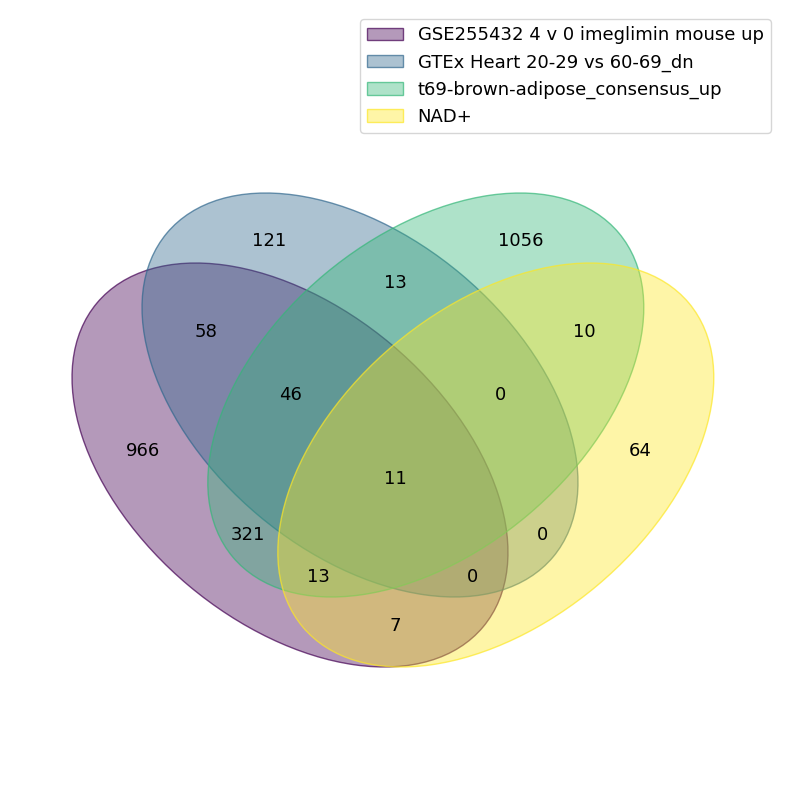

In [ ]:
term_1 = crossing['Term1']
term_2 = crossing['Term2']
term_3 = crossing['Term3']
term_4 = crossing['Term4']

set_1 = rummageodrug[term_1.upper()]
set_2 = gtexaging[term_2]
set_3 = motrpac[term_3]
set_4 = metabolomics[term_4]

plt.figure(figsize=(8,8), dpi=300)
venn({term_1:set_1, term_2:set_2, term_3:set_3, term_4:set_4})
plt.tight_layout()
plt.savefig(f'{report_dir}/figures/venn_diagram.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{report_dir}/figures/venn_diagram.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

### Bar Chart

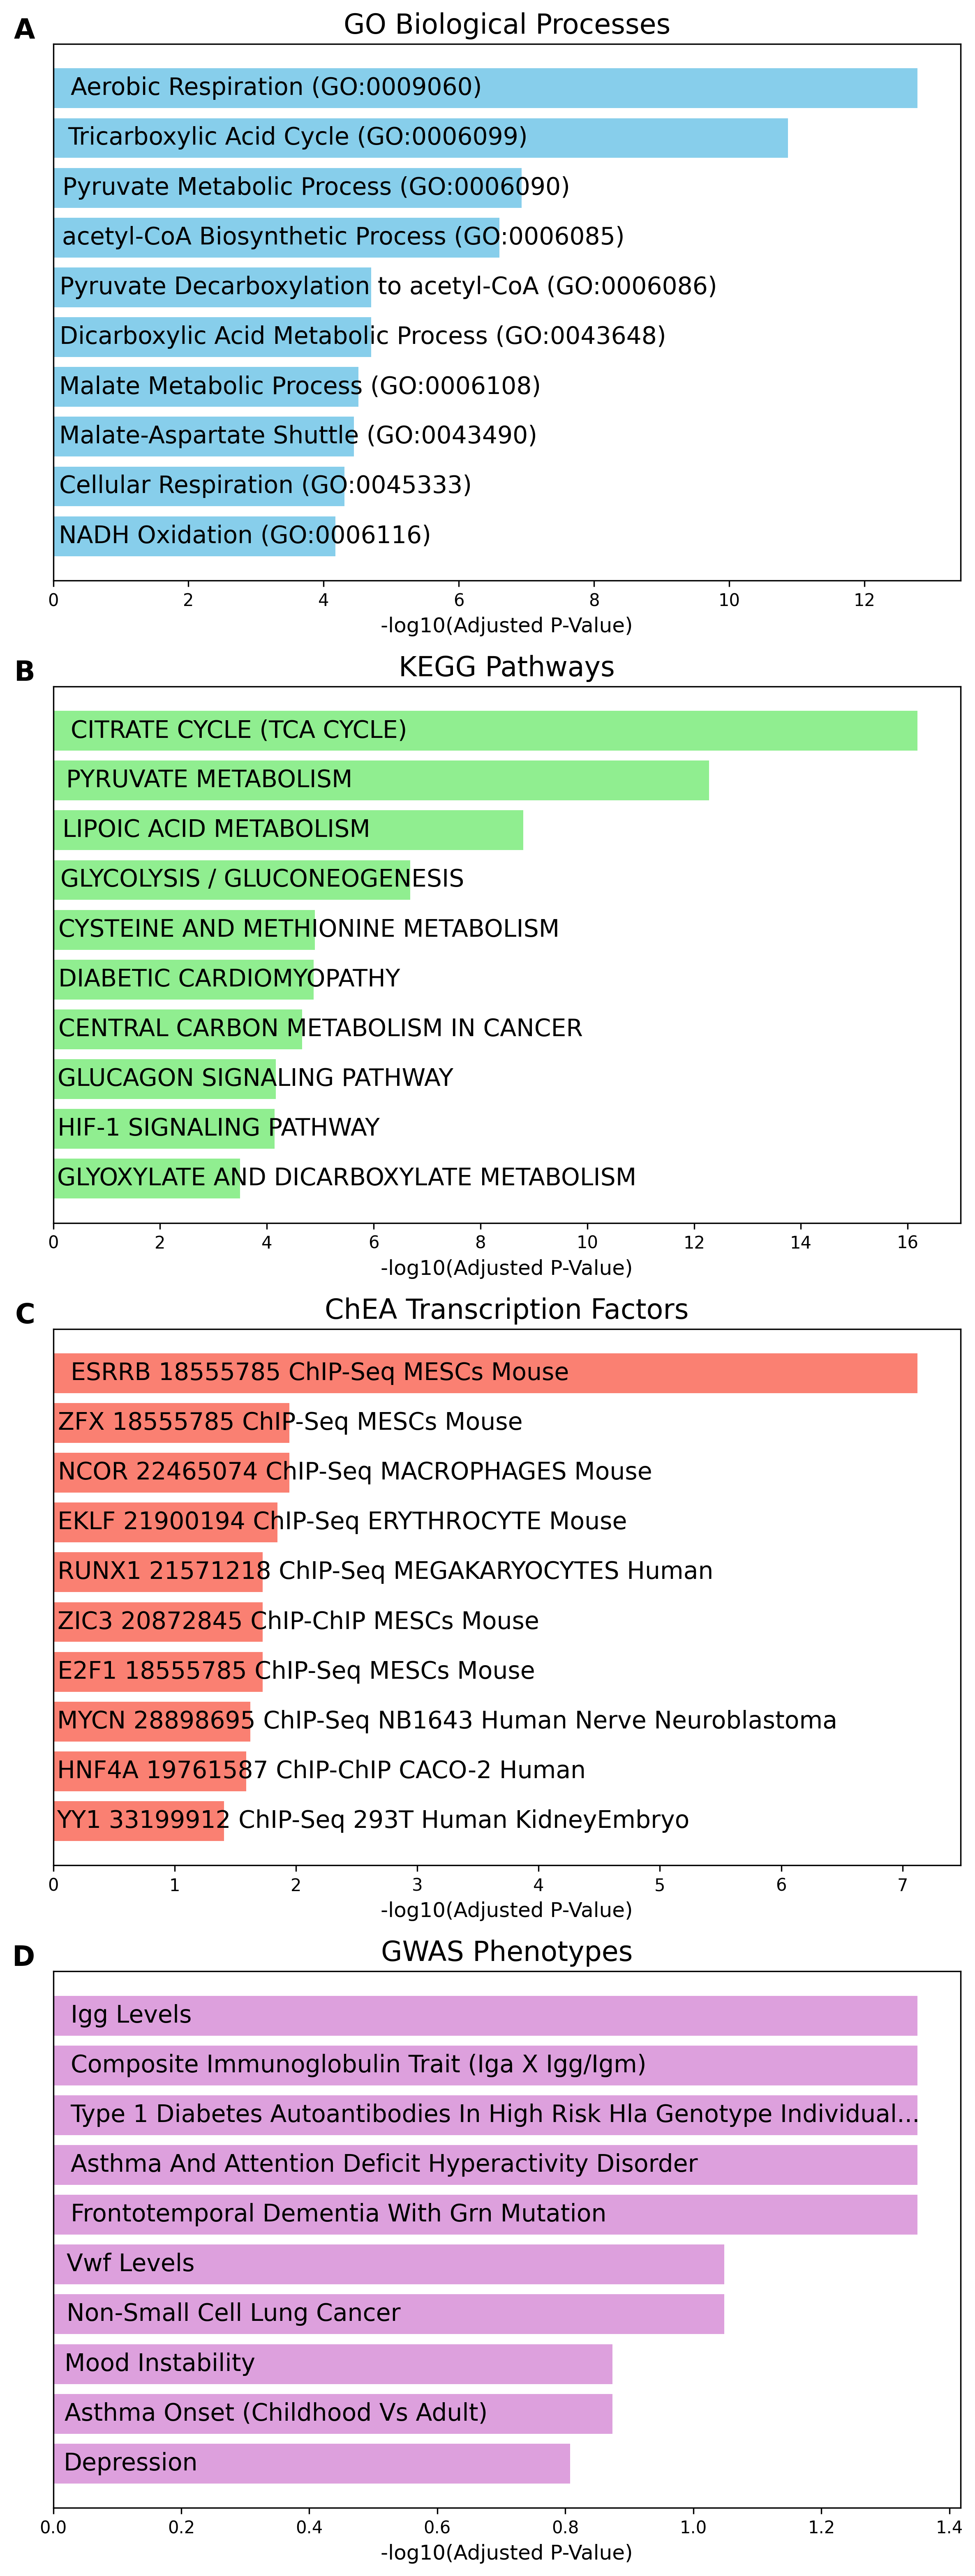

In [46]:
fig, axes = plt.subplots(4, 1, figsize=(8,21), dpi=300)

titles = ["GO Biological Processes", "KEGG Pathways", "ChEA Transcription Factors", "GWAS Phenotypes"]
colors = ["skyblue","lightgreen","salmon","plum"]
panel_labels = ["A", "B", "C", "D"]

for ax, i, title, color, label in zip(axes.flatten(), range(4), titles, colors, panel_labels):
    top = dfs[i][['Term name','Adjusted p-value']][:10][::-1]
    top['Term name'] = top['Term name'].map(truncate)
    top['-log10p'] = top['Adjusted p-value'].apply(np.log10).apply(lambda x: x*-1)

    bars = ax.barh(range(len(top)), top['-log10p'], color=color)

    # Remove y-axis ticks
    ax.set_yticks([])
    ax.set_yticklabels([])

    # Titles / labels
    ax.set_title(title, fontsize=16, fontweight='normal')
    ax.set_xlabel("-log10(Adjusted P-Value)", fontsize=12)

    # ---- Labels INSIDE bars ----
    for i, (term, z) in enumerate(zip(top['Term name'], top['-log10p'])):
        ax.text(
            z * 0.02,         # small left padding inside bar
            i,
            term,
            va='center',
            ha='left',
            fontsize=14,
            weight=525,
            color='black',
            clip_on=True
        )

    # Panel label
    ax.text(-0.02, 1.05, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(f'{report_dir}/figures/enrichment_bar.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{report_dir}/figures/enrichment_bar.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

### Template

In [196]:
env = jinja2.Environment(
    loader=jinja2.PackageLoader('template'),
    variable_start_string='(((',
    variable_end_string=')))',
)
template = env.get_template("paper.tex")

genes = crossing["Genes"].split(" ")
n_genes = len(genes)

In [197]:
rendered = template.render(
    title=report_title,
    abstract=revised_abstract,
    dataset_info=dataset_info,
    introduction=revised_introduction,
    terms = terms,
    p_value=crossing["p-value"],
    jaccard=crossing["Jaccard"],
    n_genes=n_genes,
    rank=1,
    intersecting_genes= ", and ".join(", ".join(genes).rsplit(", ",1)),
    n_sets="four",
    gene_summaries=intersection_summary,
    enrichment_results=revised_enrichment,
    discussion=revised_discussion
)

In [198]:
shutil.copy("template/extras/ExcelAtFIT.cls", f"{report_dir}/")
shutil.copy("template/extras/cfde-reports-logo.png", f"{report_dir}/")

with open(f"{report_dir}/paper.tex", "w") as tmp:
    tmp.write(rendered)

### Bibliography

In [199]:
from Bio import Entrez
Entrez.email = os.getenv("NCBI_API_EMAIL")
Entrez.api_key = os.getenv("NCBI_API_KEY")

In [200]:
handle = Entrez.efetch(db="pubmed", id=pmid)
record = Entrez.read(handle)
handle.close()

elocation = record['PubmedArticle'][0]['MedlineCitation']['Article']['ELocationID']
gse_pmid = None
for loc in elocation:
    if loc.attributes['EIdType']=='doi':
        gse_doi = loc[:]

In [201]:
refs = {
    "CFDE":"10.1016/j.jmb.2026.169631",
    "RummaGEO":"10.1016/j.patter.2024.101072", 
    "GTEx":"10.1126/science.aaz1776",
    "MoTrPAC":"10.1016/j.cell.2020.06.004",
    "Metabolomics":"10.1093/nar/gkv1042",
    "Enrichr":"10.1002/cpz1.90",
    "GO":"10.1093/nar/gkaf1292",
    "KEGG":"10.1093/nar/gkae909",
    "ChEA":"10.1093/nar/gkz446",
    "GWASCatalog":"10.1093/nar/gkae1070",
    gse:gse_doi
}

In [202]:
bib = ""
for res,ref in refs.items():
    ref = get_bibtex_from_doi(ref)
    c = ref.split(",")
    c[0] = "@misc{"+res
    bib += ",".join(c)
for reference in gene_summary_bib.values():
    bib += reference
    bib += '\n'

In [203]:
with open(f"{report_dir}/references.bib", "w") as f:
    f.write(bib)

### Construct Report

In [8]:
import subprocess
import shutil

In [33]:
report_dir = 'imeglimin_report'
construction_result = subprocess.run(["latexmk","-pdf","-cd","-lualatex",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)

Latexmk: ====Undefined refs and citations with line #s in .tex file:
  Citation 'GeneSetCart' on page 1 undefined on input line 61
  Citation 'Harmonizome' on page 1 undefined on input line 61

Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
Latexmk: Changing directory to 'imeglimin_report/'
No existing .aux file, so I'll make a simple one, and require run of *latex.
Latexmk: applying rule 'lualatex'...
Rule 'lualatex':  Reasons for rerun
Category 'other':
  Rerun of 'lualatex' forced or previously required:
    Reason or flag: 'Initial setup'

------------
Run number 1 of rule 'lualatex'
------------
------------
Running 'lualatex  -recorder  "paper.tex"'
------------
This is LuaHBTeX, Version 1.21.0 (TeX Live 2025) 
 restricted system commands enabled.
(./paper.tex
LaTeX2e <2024-11-01> patch level 2
L3 programming layer <2025-01-18>
 (./ExcelAtFIT.cls
Document Class: ExcelAtFIT 25/01/2012, v1.0
(/usr/local/texlive/2025/texmf-dist/tex/latex/b

In [34]:
construction_result = subprocess.run(["latexmk","-cd","-c",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)


Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
No specific requests made, so using default for latexmk.
Latexmk: Changing directory to 'imeglimin_report/'
Latexmk: Doing main (small) clean up for 'paper.tex'
Latexmk: Undoing directory change




In [35]:
shutil.copy(f'{report_dir}/paper.pdf', f'{report_dir}/imgelimin_report.pdf')

'imeglimin_report/imgelimin_report.pdf'

View [paper](imeglimin_report/imgelimin_report.pdf)

## Article 2: Metformin - RummaGEO Drug x GTEx Aging x MoTrPAC x Metaboolomics

In [157]:
report_dir = 'metformin_report'
if not os.path.exists(f'{report_dir}/figures'):
    os.makedirs(f'{report_dir}/figures')
if not os.path.exists(f'{report_dir}/extras'):
    os.makedirs(f'{report_dir}/extras')

In [8]:
crossings = pd.read_csv('rummageodrug_gtexaging_motrpac_mwmetabolites.tsv', sep='\t', index_col=0)
crossings['Term1'] = crossings['Term1'].apply(clean_term)
crossings

,Term1,Term1 Length,Term2,Term2 Length,Term3,Term3 Length,Term4,Term4 Length,p-value,Jaccard,Overlap,Genes
0,GSE255432 4 v 0 imeglimin mouse up,1422,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,1.144562e-13,0.004095,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
1,GSE179531 1 v 0 metformin mouse up,1586,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,2.646534e-13,0.003868,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
2,"GSE226114,GSE226116 2 v 0 doxorubicin mouse dn",920,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_male_8w_dn,338,NAD+,105,3.766607e-13,0.006886,9,DLAT DLD DLST IDH3B MDH2 NDUFS1 NDUFS2 PDHA1 PDHB
3,GSE255432 7 v 2 imeglimin mouse dn,644,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_male_8w_dn,338,NAD+,105,4.462835e-13,0.008654,9,DLAT DLD DLST IDH3B MDH2 NDUFS1 NDUFS2 PDHA1 PDHB
4,"GSE226114,GSE226116 1 v 0 doxorubicin mouse dn",1666,GTEx Heart 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,4.555056e-13,0.003715,11,DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,GSE158834 1 v 9 palmitic acid human dn,1043,GTEx AdiposeTissue 20-29 vs 30-39_dn,249,t69-brown-adipose_consensus_up,1470,Acetyl-CoA,36,2.977532e-04,0.001193,3,CS DLAT PDHA1
4996,GSE158834 1 v 9 palmitic acid human dn,1043,GTEx AdiposeTissue 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,Pyruvic acid,24,2.977532e-04,0.001193,3,DLAT LDHB PDHA1
4997,GSE126463 0 v 3 pomalidomide human dn,924,GTEx Colon 20-29 vs 60-69_dn,249,t69-brown-adipose_consensus_up,1470,NAD+,105,2.977532e-04,0.001191,3,DLAT IDH3A NDUFS1
4998,GSE210655 1 v 2 cisplatin mouse up,1059,GTEx Esophagus 20-29 vs 70-79_dn,249,t69-brown-adipose_consensus_up,1470,Succinyl-CoA,10,2.977532e-04,0.001190,3,DLD MMUT SUCLG2


In [9]:
crossing = crossings.loc[13].astype(str)
terms = list(crossings.loc[13, ['Term1', 'Term2', 'Term3', 'Term4']])
gene_set = crossings.loc[13, 'Genes'].split(' ')
crossing

Term1                          GSE179531 1 v 0 metformin mouse up
Term1 Length                                                 1586
Term2                                GTEx Heart 20-29 vs 60-69_dn
Term2 Length                                                  249
Term3                              t69-brown-adipose_consensus_up
Term3 Length                                                 1470
Term4                                                  Coenzyme A
Term4 Length                                                   98
p-value                                              3.692721e-12
Jaccard                                        0.0035223670306445
Overlap                                                        10
Genes           ALAS1 CS DLAT DLD DLST HADHB PDHA1 PDHB SUCLA2...
Name: 13, dtype: object

In [10]:
rummageo_mouse_meta = json.load(open('meta/mouse-gse-processed-meta.json', 'r'))

In [11]:
rummageo_sample_info = (
    rummageo_mouse_meta[terms[0].split(' ')[0]]['titles']
)
rummageo_sample_info

{'0': 'murine preadipocyte cells cell line 3t3 l1 strain c57bl/6 dexamethasone/3 isobutyl 1 methylxanthine/insulin',
 '1': 'murine preadipocyte cells cell line 3t3 l1 strain c57bl/6 untreated'}

In [12]:
summaries = {}
for gene in tqdm(gene_set):
    summary_text, references = format_deepdive(gene)
    summaries[gene] = {
        "summary": summary_text,
        "references": references,
    }

100%|██████████| 10/10 [00:00<00:00, 2478.32it/s]


### Enrichment Results

In [13]:
ENRICHR_URL = 'https://maayanlab.cloud/Enrichr'
enrichment_result_columns = ['Rank', 'Term name', 'P-value', 'Odds ratio', 'Combined score', 'Overlapping genes', 'Adjusted p-value', 'Old p-value', 'Old adjusted p-value']

In [14]:
genes_str = '\n'.join(gene_set)
description = f'Crossing of {terms[0]}, {terms[1]}, {terms[2]}, and {terms[3]} gene sets'

payload = {
    'list': (None, genes_str),
    'description': (None, description)
}

response = requests.post(f"{ENRICHR_URL}/addList", files=payload)
if not response.ok:
    raise Exception('Error analyzing gene list')

enrichr_gene_set = json.loads(response.text)
user_list_id = enrichr_gene_set['userListId']
enrichr_gene_set

{'shortId': 'be113a69de41ccf7d8be055cf9f2c50e', 'userListId': 121276045}

In [16]:
GO_BP_25 = enrich(user_list_id, 'GO_Biological_Process_2025')
kegg_26 = enrich(user_list_id, 'KEGG_2026')
ChEA_2022 = enrich(user_list_id, 'ChEA_2022')
GWAS = enrich(user_list_id, 'GWAS_Catalog_2025')

In [17]:
subset_columns = ['Term name', 'P-value', 'Adjusted p-value', 'Combined score']
dfs = [GO_BP_25, kegg_26, ChEA_2022, GWAS]
enrichment_results = {
    'GO_BP_25': GO_BP_25.loc[:10,subset_columns].to_json(),
    'kegg_26': kegg_26.loc[:10,subset_columns].to_json(),
    'ChEA_2022': ChEA_2022.loc[:10,subset_columns].to_json(),
    'GWAS Catalog 2025': GWAS.loc[:10,subset_columns].to_json()
}

### Article Generation

In [37]:
gene_summaries = {gene:summary["summary"] for gene,summary in summaries.items()}

In [214]:
dataset_1_processing = f'''RummaGEO is a webserver developed to enable signature identification from uniformly aligned GEO studies \\autocite{{RummaGEO}}.
Conditions of samples are automatically identified and grouped before differential expression analysis is performed.
The RummaGEO Gene Perturbation Signatures dataset was processed by querying the RummaGEO metadata search API.
Signatures containing a drug where one condition included a term included in any of a list of control terms and the other condition mentioned a perturbation term were kept.
Genes for each signature were then retrieved to construct a GMT file.'''

dataset_2_processing = f'''The GTEx Tissue-Specific Aging dataset was constructed using gene expression count data from the Genotype Tissue Expression (GTEx) Portal \\autocite{{GTEx}}.
Sample metadata was filtered to create groups of samples with matching tissue type and donor age ranges.
Differential expression analysis was then performed comparing young (20-29) tissue samples against older samples from matched tissue types to create tissue-specific aging signatures.
These signatures were then filtered to create gene sets and a GMT.'''

dataset_3_processing = f'''The MoTrPAC Rat Endurance Exercise Training dataset was processed from transcriptomic data from the Molecular Transducers of Physical Activity Consortium (MoTrPAC) Data Hub \\autocite{{MoTrPAC}}.
Differential expression data from MoTrPAC was filtered to keep associations where gene expression changed over the course of 8 weeks of endurance exercise.
Exercise tissue samples were differentiated by sex and tissue type in addition to exercise timepoint.
The downloaded data also included training data of genes with modulated expression over the training window in addition to the timewise data.
The differential expression data was filtered to create gene sets and a GMT.'''

dataset_4_processing = f'''The Metabolomics Workbench Enzyme-Metabolite Associations dataset was processed from an edgelist of protein-metabolite associations \\autocite{{Metabolomics}}.
The curated input data used provided directly by the Metabolomics Workbench team.
The edgelist was harmonized to create gene sets to create a GMT.'''

In [215]:
datasets=["RummaGEO Drug Perturbation Signatures", "GTEx Tissue-Specific Aging Signatures", "MoTrPAC Rat Endurance Exercise Training Transcriptomics", "Metabolomics Workbench Metabolites"]
resources = ['RummaGEO', 'GTEx', 'MoTrPAC', 'Metabolomics']

dataset_info = {
    1:{
        "name":datasets[0],
        "resource":resources[0],
        "processing":dataset_1_processing
    },
    2:{
        "name":datasets[1],
        "resource":resources[1],
        "processing":dataset_2_processing
    },
    3:{
        "name":datasets[2],
        "resource":resources[2],
        "processing":dataset_3_processing
    },
    4:{
        "name":datasets[3],
        "resource":resources[3],
        "processing":dataset_4_processing
    }

}

### Introduction

In [40]:
prompt = f'''
Introduce the gene sets found in this top-ranked crossing between 4 datasets. cMake sure to include each gene 
set in the provided top-ranked crossing to provide context. Your response will be inserted into a template, so
do not inclue an introduction or conclusion. Return LaTeX compliant plaintext paragraph. Do not use any LaTeX expressions.
RummaGEO condition titles: {rummageo_sample_info}. Replace the groups in the term with the appriate titles, the numbres
are not useful to the reader.
Crossing: {crossing[["Term1", "Term2", "Term3", "Term4"]]}
'''

In [61]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

introduction = sanitize(response.output[-1].content[0].text)
print(introduction)

The crossing integrates four distinct gene-set signatures: (1) the metformin-responsive mouse profile from GSE179531, representing genes up-regulated in metformin-treated murine preadipocyte cells (dexamethasone/3-isobutyl-1-methylxanthine/insulin) compared with untreated murine preadipocyte cells; (2) the GTEx heart age-related signature, comprising genes down-regulated in heart tissue of individuals aged 20-29 relative to those aged 60-69; (3) the t69-brown-adipose consensus set, containing genes consistently up-regulated in brown adipose tissue across the t69 study; and (4) the Coenzyme A gene set, which captures genes involved in Coenzyme A biosynthesis and metabolism.


### Methods/Results

#### Gene Summaries

In [110]:
ast_gene_summaries = [deepdive_summaries[gene] for gene in gene_set]
summary_prompt_1 = f'''
Create a bullet point list outlining 2 or 3 paragraph summarizing the common functions and associations
of this gene set using the provided summaries. Include a header bullet point for each paragraph.
At the end of each sub-bullet point, include the relevant citations that provide this information, keeping the 
numbering for each gene's references (e.g. [DLAT_1, PDHB_3]). You must not renumber or group references.
Gene summaries: {gene_summaries}
'''

In [111]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": summary_prompt_1
        }
    ],
)

planning_sumamry = response.output[-1].content[0].text
print(planning_sumamry)

- **Paragraph 1 – Core mitochondrial enzymes that drive oxidative energy production**  
  - The pyruvate dehydrogenase complex (PDHA1 + PDHB + DLAT + DLD) converts glycolytic pyruvate into acetyl‑CoA, directly feeding the tricarboxylic acid (TCA) cycle; CS catalyzes the first committed step of the TCA cycle, while DLST (E2 of α‑KGDHC) and the succinyl‑CoA synthetase subunits (SUCLA2 and SUCLG1) sustain downstream carbon flow and ATP generation.  Fatty‑acid β‑oxidation is completed by the mitochondrial trifunctional protein β‑subunit (HADHB), which also produces acetyl‑CoA, and the first, rate‑limiting step of heme biosynthesis (ALAS1) is coupled to mitochondrial acetyl‑CoA availability.  Together, these enzymes constitute the central hub that links glycolysis, fatty‑acid catabolism, and heme synthesis to mitochondrial respiration.  **[ALAS1_1, ALAS1_2, ALAS1_3; CS_1, CS_2; DLAT_1, DLAT_2, DLAT_3; DLD_1, DLD_2, DLD_3; DLST_1, DLST_2, DLST_3, DLST_4, DLST_8; HADHB_1, HADHB_2, HADHB_3, HA

In [122]:
ast_prompt = f'''
Write an abstract syntax tree summary using the example AST for format,
the bullet point outline for structure, and the appropriate references
from the summaries. Verify that the included references are appropriate.
You must not renumber, change, or group references, leave them exactly 
as they are in the input, in the form "[gene]_[refnumber]". Return only
 the AST. You must generate valid JSON.
Example AST: {ast_example}
Planning outline: {planning_sumamry}
Gene summaries: {ast_gene_summaries}
'''

In [123]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": ast_prompt
        }
    ],
    temperature=0.0
)

ast_intersection_summary = response.output[-1].content[0].text
print(ast_intersection_summary)

{
  "type": "root",
  "children": [
    {
      "type": "p",
      "children": [
        {
          "type": "t",
          "text": "Core mitochondrial enzymes that drive oxidative energy production include "
        },
        {
          "type": "t",
          "text": "ALAS1"
        },
        {
          "type": "fg",
          "children": [
            {
              "type": "fg_f",
              "ref": "ALAS1_1"
            }
          ]
        },
        {
          "type": "t",
          "text": ", "
        },
        {
          "type": "t",
          "text": "citrate synthase (CS)"
        },
        {
          "type": "fg",
          "children": [
            {
              "type": "fg_f",
              "ref": "CS_1"
            }
          ]
        },
        {
          "type": "t",
          "text": ", "
        },
        {
          "type": "t",
          "text": "dihydrolipoamide acetyltransferase (DLAT)"
        },
        {
          "type": "fg",
          "ch

In [125]:
with open('ast_summary_13.json', 'w') as f:
    f.write(ast_intersection_summary.replace("'",'"').replace('```json\n','').replace('\n```',''))

In [126]:
with open('ast_summary_13.json', 'r') as f:
    s = json.load(f)

len(s)

2

In [137]:
intersection_summary = ast_to_latex(s)
print(intersection_summary)

Core mitochondrial enzymes that drive oxidative energy production include ALAS1\autocite{ALAS1_1}, citrate synthase (CS)\autocite{CS_1}, dihydrolipoamide acetyltransferase (DLAT)\autocite{DLAT_1}, dihydrolipoamide dehydrogenase (DLD)\autocite{DLD_1}, dihydrolipoamide S-succinyltransferase (DLST)\autocite{DLST_1}, mitochondrial trifunctional protein $\beta$-subunit (HADHB)\autocite{HADHB_1}, pyruvate dehydrogenase E1$\alpha$ (PDHA1)\autocite{PDHA1_1}, pyruvate dehydrogenase E1$\beta$ (PDHB)\autocite{PDHB_1}, SUCLA2\autocite{SUCLA2_1}, and SUCLG1\autocite{SUCLG1_1}.

Coordinated transcriptional and post-translational control of mitochondrial metabolism involves several layers. ALAS1\autocite{ALAS1_1} transcription is up-regulated by nuclear receptors such as PPAR$\alpha$ and co-activators including PGC-1$\alpha$/$\beta$, NRF-1 and ERR$\alpha$. PDHA1\autocite{PDHA1_1} activity is fine-tuned by reversible serine/tyrosine phosphorylation and by extracellular cues such as growth-factor and i

In [128]:
gene_summary_references = {
        f'{g}_{i}':gr
        for g in gene_set
        for i,gr in summaries[g]['references'].items() 
}

len(gene_summary_references)

98

In [130]:
gene_summary_bib = {
    key: get_gene_bibtex_from_doi(key,ref)
    for key, ref in gene_summary_references.items()
    if key in ast_intersection_summary
}

In [131]:
for reference in gene_summary_bib.values():
    print(reference)

@misc{ALAS1_1, title={Comparative Analysis of Gene Regulation by the Transcription Factor PPARα between Mouse and Human}, volume={4}, ISSN={1932-6203}, url={http://dx.doi.org/10.1371/journal.pone.0006796}, DOI={10.1371/journal.pone.0006796}, number={8}, journal={PLoS ONE}, publisher={Public Library of Science (PLoS)}, author={Rakhshandehroo, Maryam and Hooiveld, Guido and Müller, Michael and Kersten, Sander}, editor={Laudet, Vincent}, year={2009}, month=aug, pages={e6796} }

@misc{CS_1, title={Exercise induces transient transcriptional activation of the PGC‐1α gene in human skeletal muscle}, volume={546}, ISSN={1469-7793}, url={http://dx.doi.org/10.1113/jphysiol.2002.034850}, DOI={10.1113/jphysiol.2002.034850}, number={3}, journal={The Journal of Physiology}, publisher={Wiley}, author={Pilegaard, Henriette and Saltin, Bengt and Neufer, P. Darrell}, year={2003}, month=feb, pages={851–858} }

@misc{DLAT_1, title={Sirtuin 4 Is a Lipoamidase Regulating Pyruvate Dehydrogenase Complex Activi

#### Enrichment Analysis

In [283]:
prompt = f'''
Create a one paragraph to summarize the results and highlight any interesting terms.
Do not include any scores or values, they will be handled separately.
Do not use LaTeX expressions. Do not use specialcharacters. 
Return only plain text that will not cause encoding/decoding issues.
Crossing: {crossing.to_json()}
RummaGEO Samples: {rummageo_sample_info}
Enrichment Results: {enrichment_results}
'''

In [284]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

enrichment = sanitize(response.output[-1].content[0].text)
print(enrichment)

The analysis of metformin-treated versus untreated murine 3T3-L1 preadipocytes revealed a coordinated up-regulation of mitochondrial metabolic genes such as ALAS1, CS, DLAT, DLD, DLST, HADHB, PDHA1, PDHB, SUCLA2 and SUCLG1, linking the response to core Coenzyme A biology. Enrichment testing highlighted strong signals for the tricarboxylic acid cycle, aerobic respiration, succinyl-CoA and acetyl-CoA biosynthetic processes, as well as pyruvate decarboxylation and purine catabolism, underscoring an activation of oxidative metabolism. Corresponding KEGG pathways reinforced this picture with prominence of the citrate cycle, lipoic acid metabolism, pyruvate metabolism, glycolysis and gluconeogenesis, and fatty acid elongation. Transcription factor analysis pointed to regulators such as ESRRB, HNF4A, TAF7L, E2F1, CREM, ZFX, PPARA and LXR, suggesting that nuclear receptors governing lipid and energy homeostasis are engaged. Finally, the gene set showed overlap with GWAS traits related to drug-

### Discussion

In [285]:
prompt = f'''
Write 1 or two concise, LaTeX-compliant plain text discussion paragraphs. Using 
the gene summaries, crossed terms of this 4-way gene set crossing, and enrichment
analysis results, hypothesize why the drug perturbation might modulate exercise 
and aging. Do not include any special symbols.
Terms: {terms}
Gene summaries: {gene_summaries}
Enrichment results: {enrichment}
'''

In [286]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

discussion = sanitize(response.output[-1].content[0].text)
print(discussion)

The metformin-treated 3T3-L1 preadipocyte signature (GSE179531 1 v 0 metformin mouse up) is dominated by genes that encode core Coenzyme A-dependent enzymes of the tricarboxylic acid cycle and pyruvate dehydrogenase complex (ALAS1, CS, DLAT, DLD, DLST, HADHB, PDHA1, PDHB, SUCLA2, SUCLG1).  Their coordinated up-regulation points to an activation of oxidative phosphorylation, fatty-acid $\beta$-oxidation and mitochondrial biosynthesis, processes that are also induced by endurance exercise.  Transcription-factor enrichment implicates nuclear receptors that govern lipid and energy homeostasis (PPARA, HNF4A, LXR), further linking the drug response to the metabolic programme normally triggered by physical activity.

When the same gene set is crossed with the GTEx heart ageing contrast (GTEx Heart 20-29 vs 60-69\_dn) and the brown-adipose consensus up-regulation (t69-brown-adipose\_consensus\_up), the metformin-induced genes appear to be down-regulated in older heart tissue but up-regulated i

### Abstract

In [287]:
report = f''''
Title: Crossing Gene Sets from RummaGEO, GTEx, MoTrPAC, and Metabolomics Workbench Reveals Metformin as a Potential Modulator of Aging, Exercise, and Metabolism
Introduction: {introduction}
Methods and Results:
Dataset Processing: {dataset_info}
Gene Summaries: {intersection_summary}
Enrichment Analysis: {enrichment}
Discussion: {discussion}
'''

In [288]:
prompt = f'''
Write a concise, LaTeX-compliant plaintext abstract. Introduce the problem of discrete
datasets, summarize why crossing Common Fund datasets is useful, what was done, and 
what was found. The text should be about 200 words and contain only plain text (no symbols).
Do not include statistics or a header and use normal hyphens and spaces in your response.
Report: {report}
'''

In [289]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

abstract = sanitize(response.output[-1].content[0].text)
print(abstract)

The analysis of large-scale biomedical data is often hampered by the discrete nature of publicly available resources, each of which provides a limited view of biological processes. Integrating gene-set signatures from multiple Common Fund initiatives can reveal connections that are invisible within any single dataset. To explore this opportunity we extracted four curated gene-set collections: a metformin-responsive mouse preadipocyte signature from the RummaGEO drug perturbation database, an age-related heart signature from GTEx, a consensus brown-adipose up-regulation set from the MoTrPAC endurance-exercise study, and a Coenzyme A metabolism set derived from Metabolomics Workbench enzyme-metabolite associations. Each collection was processed into a GMT format and then intersected to identify genes shared across the drug, aging, exercise, and metabolic pathways. The overlapping genes were dominated by core mitochondrial enzymes of the tricarboxylic-acid cycle and the pyruvate dehydroge

### Venn Diagram

In [147]:
rummageodrug = load_rummageo_gmt('cfgmts/rummageodrug.gmt')
gtexaging = load_gmt('cfgmts/gtexagingsignatures_up.gmt', '_up') | load_gmt('cfgmts/gtexagingsignatures_dn.gmt', '_dn')
motrpac = load_gmt('cfgmts/motrpac_up.gmt', '_up') | load_gmt('cfgmts/motrpac_dn.gmt', '_dn')
metabolomics = load_gmt('cfgmts/mwmetabolites_up.gmt')

<Figure size 2400x2400 with 0 Axes>

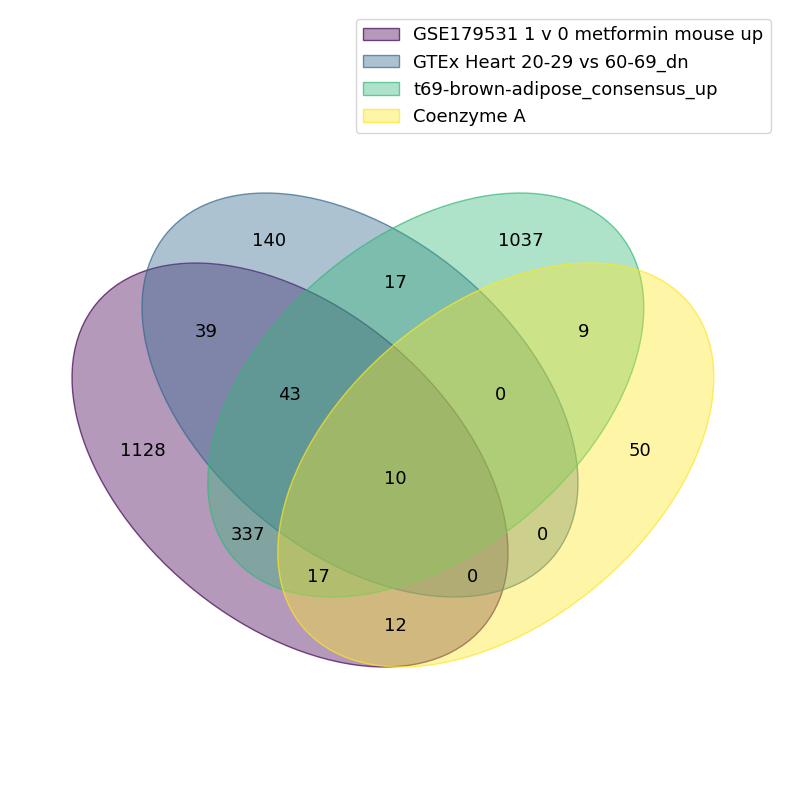

In [148]:
term_1 = crossing['Term1']
term_2 = crossing['Term2']
term_3 = crossing['Term3']
term_4 = crossing['Term4']

set_1 = rummageodrug[term_1.upper()]
set_2 = gtexaging[term_2]
set_3 = motrpac[term_3]
set_4 = metabolomics[term_4]

plt.figure(figsize=(8,8), dpi=300)
venn({term_1:set_1, term_2:set_2, term_3:set_3, term_4:set_4})
plt.tight_layout()
#os.makedirs("report_construction/figures", exist_ok=True)
plt.savefig(f'{report_dir}/figures/venn_diagram.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

### Bar Chart

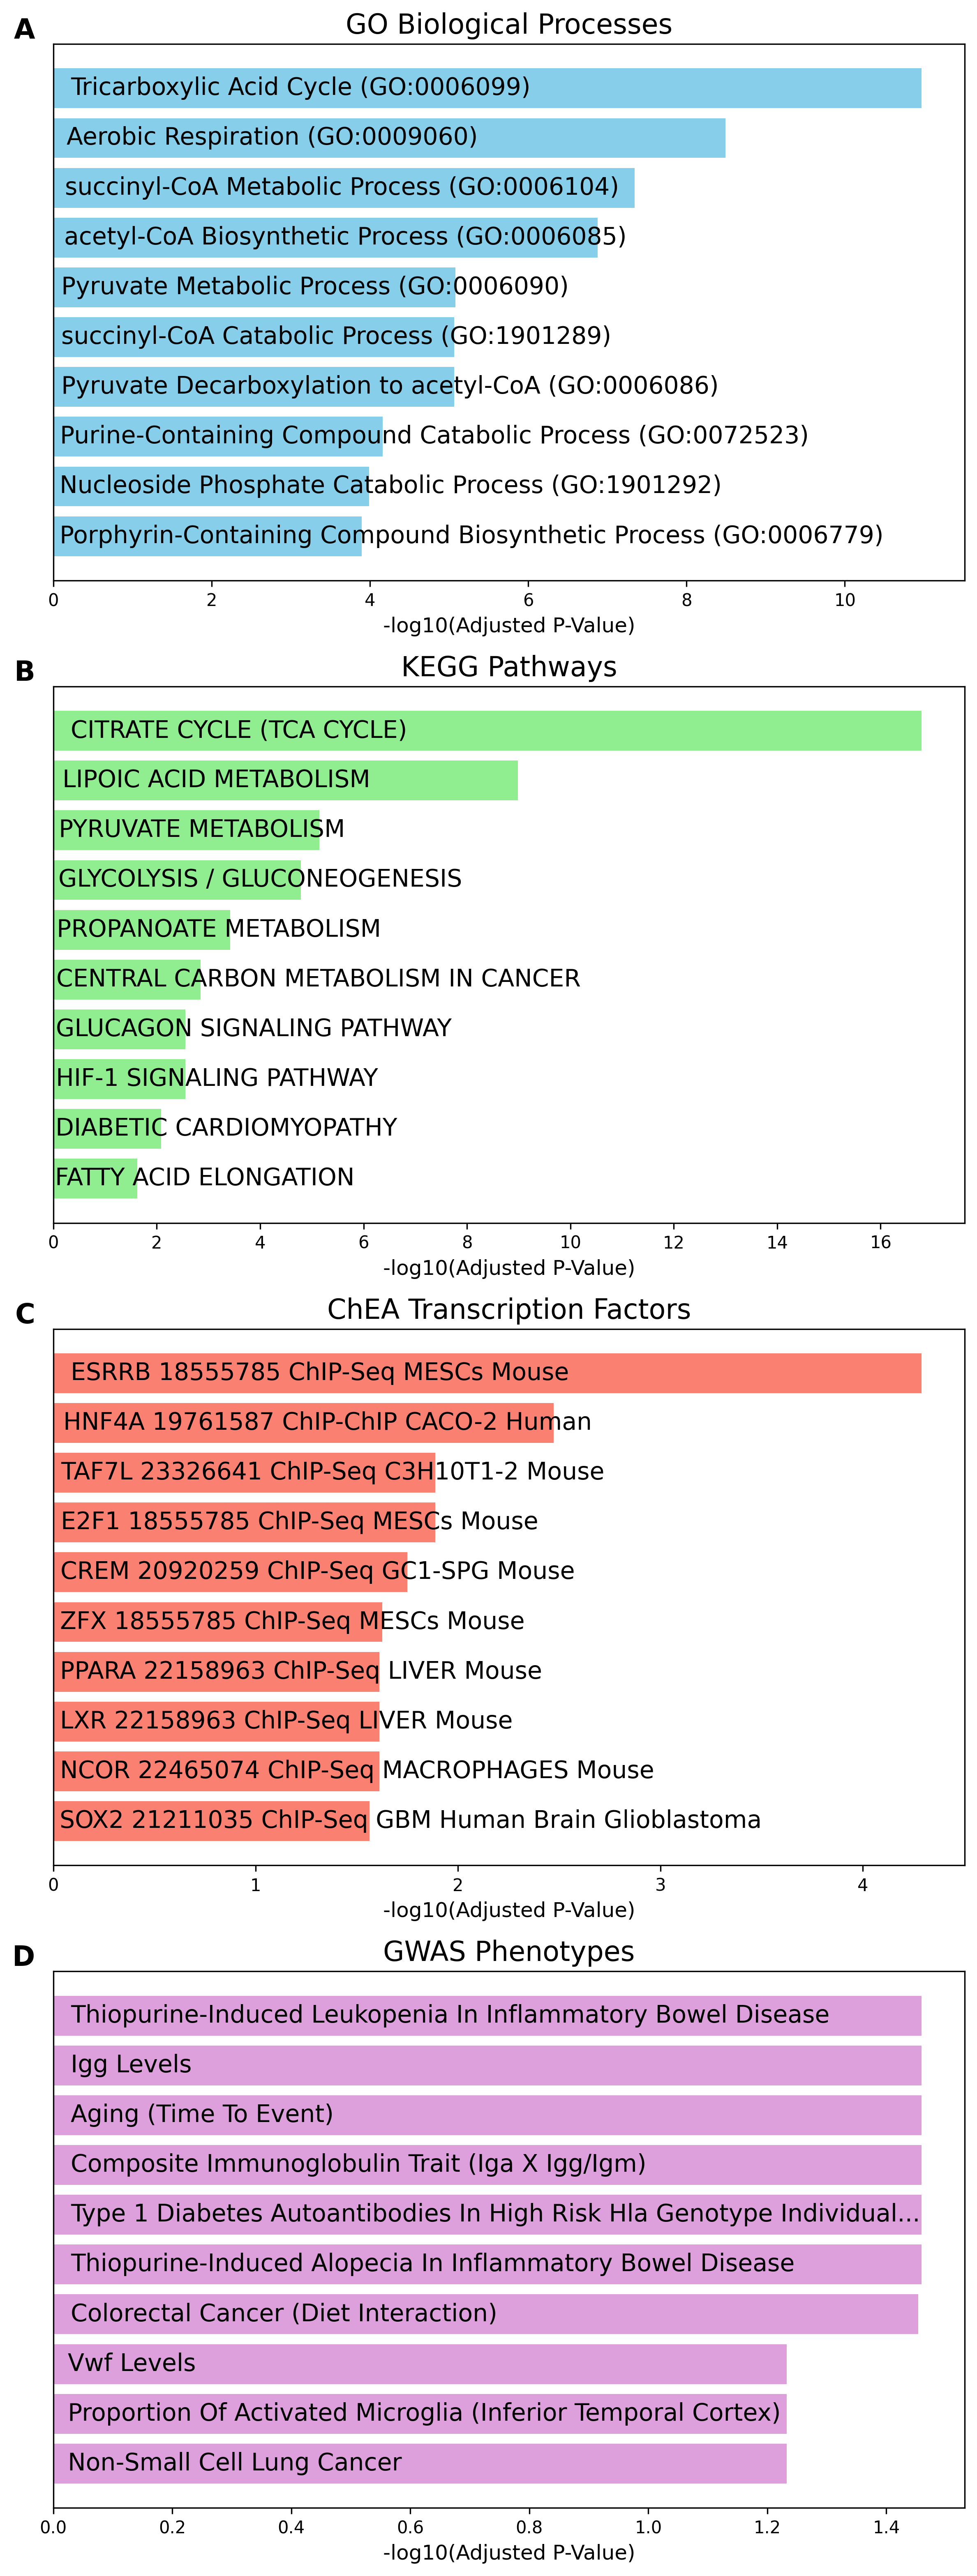

In [150]:
fig, axes = plt.subplots(4, 1, figsize=(8,21), dpi=300)

titles = ["GO Biological Processes", "KEGG Pathways", "ChEA Transcription Factors", "GWAS Phenotypes"]
colors = ["skyblue","lightgreen","salmon","plum"]
panel_labels = ["A", "B", "C", "D"]

for ax, i, title, color, label in zip(axes.flatten(), range(4), titles, colors, panel_labels):
    top = dfs[i][['Term name','Adjusted p-value']][:10][::-1]
    top['Term name'] = top['Term name'].map(truncate)
    top['-log10p'] = top['Adjusted p-value'].apply(np.log10).apply(lambda x: x*-1)

    bars = ax.barh(range(len(top)), top['-log10p'], color=color)

    # Remove y-axis ticks
    ax.set_yticks([])
    ax.set_yticklabels([])

    # Titles / labels
    ax.set_title(title, fontsize=16, fontweight='normal')
    ax.set_xlabel("-log10(Adjusted P-Value)", fontsize=12)

    # ---- Labels INSIDE bars ----
    for i, (term, z) in enumerate(zip(top['Term name'], top['-log10p'])):
        ax.text(
            z * 0.02,         # small left padding inside bar
            i,
            term,
            va='center',
            ha='left',
            fontsize=14,
            weight=525,
            color='black',
            clip_on=True
        )

    # Panel label
    ax.text(-0.02, 1.05, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(f'{report_dir}/figures/enrichment_bar.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

### Template

In [290]:
env = jinja2.Environment(
    loader=jinja2.PackageLoader('template'),
    variable_start_string='(((',
    variable_end_string=')))',
)
template = env.get_template("paper.tex")

title = "Crossing Gene Sets from RummaGEO, GTEx, MoTrPAC, and Metabolomics Workbench Reveals Metformin as a Potential Modulator of Aging, Exercise, and Metabolism"

genes = crossing["Genes"].split(" ")
n_genes = len(genes)

In [291]:
rendered = template.render(
    title=title,
    abstract=abstract,
    dataset_info=dataset_info,
    introduction=introduction,
    p_value=crossing["p-value"],
    jaccard=crossing["Jaccard"],
    n_genes=n_genes,
    intersecting_genes= ", and ".join(", ".join(genes).rsplit(", ",1)),
    dataset_1_processings=dataset_info,
    n_sets="four",
    gene_summaries=intersection_summary,
    enrichment_results=enrichment,
    discussion=discussion
)

In [292]:
shutil.copy("template/extras/ExcelAtFIT.cls", f"{report_dir}/")
shutil.copy("template/extras/cfde-reports-logo.png", f"{report_dir}/")

with open(f"{report_dir}/paper.tex", "w") as tmp:
    tmp.write(rendered)

### Bibliography

In [294]:
refs = {
    "CFDE":"10.1016/j.jmb.2026.169631",
    "RummaGEO":"10.1016/j.patter.2024.101072", 
    "GTEx":"10.1126/science.aaz1776",
    "MoTrPAC":"10.1016/j.cell.2020.06.004",
    "Metabolomics":"10.1093/nar/gkv1042",
    "Enrichr":"10.1002/cpz1.90",
    "GO":"10.1093/nar/gkaf1292",
    "KEGG":"10.1093/nar/gkae909",
    "ChEA":"10.1093/nar/gkz446",
    "GWASCatalog":"10.1093/nar/gkae1070"
}

In [295]:
bib = ""
for res,ref in refs.items():
    ref = get_bibtex_from_doi(ref)
    c = ref.split(",")
    c[0] = "@misc{"+res
    bib += ",".join(c)
for reference in gene_summary_bib.values():
    bib += reference
    bib += '\n'

In [296]:
with open(f"{report_dir}/references.bib", "w") as f:
    f.write(bib)

### Construct Report

In [298]:
construction_result = subprocess.run(["latexmk","-pdf","-cd","-lualatex",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)


Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
Latexmk: Changing directory to 'metformin_report/'
No existing .aux file, so I'll make a simple one, and require run of *latex.
Latexmk: applying rule 'lualatex'...
Rule 'lualatex':  Reasons for rerun
Category 'other':
  Rerun of 'lualatex' forced or previously required:
    Reason or flag: 'Initial setup'

------------
Run number 1 of rule 'lualatex'
------------
------------
Running 'lualatex  -recorder  "paper.tex"'
------------
This is LuaHBTeX, Version 1.21.0 (TeX Live 2025) 
 restricted system commands enabled.
(./paper.tex
LaTeX2e <2024-11-01> patch level 2
L3 programming layer <2025-01-18>
 (./ExcelAtFIT.cls
Document Class: ExcelAtFIT 25/01/2012, v1.0
(/usr/local/texlive/2025/texmf-dist/tex/latex/base/ifthen.sty)
(/usr/local/texlive/2025/texmf-dist/tex/latex/tools/calc.sty)
(/usr/local/texlive/2025/texmf-dist/tex/latex/base/article.cls
Document Class: article 2024/06/29 v1.4n Standard La

In [299]:
construction_result = subprocess.run(["latexmk","-cd","-c",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)


Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
No specific requests made, so using default for latexmk.
Latexmk: Changing directory to 'metformin_report/'
Latexmk: Doing main (small) clean up for 'paper.tex'
Latexmk: Undoing directory change




In [269]:
from IPython.display import Markdown as md

md(f"View [paper]({report_dir}/paper.pdf)")

View [paper](metformin_report/paper.pdf)

In [300]:
shutil.copy(f'{report_dir}/paper.pdf', f'{report_dir}/metformin_report.pdf')

'metformin_report/metformin_report.pdf'

## Article 3: PPP1R16B - LINCS CRISPR x GTEx Aging x GlyGen

In [54]:
report_dir = 'PPP1R16B_report'
if not os.path.exists(f'{report_dir}/figures'):
    os.makedirs(f'{report_dir}/figures')
if not os.path.exists(f'{report_dir}/extras'):
    os.makedirs(f'{report_dir}/extras')

In [55]:
crossings = pd.read_csv('l1000xpr_gtexaging_glygen.tsv', sep='\t', index_col=0)
crossings

,Term1,Term1 Length,Term2,Term2 Length,Term3,Term3 Length,p-value,Jaccard,Overlap,Genes
0,XPR031_ES2.311_96H_P24_PPP1R16B down,250,GTEx Brain 20-29 vs 60-69_up,249,G82830MN,164,5.924912e-14,0.014446,9,AZGP1 BGN CFB CFH CFI CLU CP PTGDS SERPINA3
1,XPR015_YAPC.311_96H_F13_DCLK2 down,250,GTEx Muscle 20-29 vs 60-69_up,249,G43417UB,605,7.001954e-14,0.011673,12,BGN COL6A2 CP ELN FBLN2 FBLN5 ISLR LUM MFAP2 M...
2,XPR035_MCF7.311_96H_B08_PRKD1 up,250,GTEx Brain 20-29 vs 60-69_up,249,G00912UN,140,6.815310e-13,0.013115,8,C1S CFB CFH CFI CLU CP SERPINA3 VWF
3,XPR027_AGS.311_96H_I10_VSIG1 down,250,GTEx Muscle 20-29 vs 60-69_up,249,G43417UB,605,1.036439e-12,0.009615,10,BGN COL6A2 ELN FBLN2 ISLR LUM MFAP2 PCOLCE SEM...
4,XPR016_A375.311_96H_J10_FAIM2 down,250,GTEx Muscle 20-29 vs 70-79_up,249,G05724UK,262,1.153982e-12,0.012465,9,C2 C3 CD74 CLU HLA-DPA1 HLA-DRA MPZL2 PLAT PLXNB2
...,...,...,...,...,...,...,...,...,...,...
4995,XPR042_IPC298.311_96H_D10_BRDN0003228153 up,250,GTEx Brain 20-29 vs 60-69_up,249,G85144OK,33,4.293143e-08,0.009823,5,AZGP1 CFH CLU CP SERPINA3
4996,XPR021_BICR6.311_96H_M03_MXRA5 up,250,GTEx Brain 20-29 vs 60-69_up,249,G85144OK,33,4.293143e-08,0.009804,5,AZGP1 CFH CFI CP SERPINA3
4997,XPR025_A375.311_96H_A14_STARD3 up,250,GTEx Brain 20-29 vs 60-69_up,249,G85144OK,33,4.293143e-08,0.009804,5,AZGP1 CFH CFI CP SERPINA3
4998,XPR040_LCLC103H.311_96H_B16_RFX5 down,250,GTEx Brain 20-29 vs 70-79_up,249,G85144OK,33,4.293143e-08,0.009804,5,AZGP1 CFH CFI CP SERPINA3


In [56]:
crossing = crossings.loc[0].copy()
crossing["p-value"] = f'{crossing.loc["p-value"]:.3e}'
crossing["Jaccard"] = f'{crossing.loc["Jaccard"]:.4f}'
crossing = crossing.astype(str)
terms = list(crossing.loc[['Term1', 'Term2', 'Term3']])
gene_set = crossing.loc['Genes'].split(' ')
crossing

Term1                  XPR031_ES2.311_96H_P24_PPP1R16B down
Term1 Length                                            250
Term2                          GTEx Brain 20-29 vs 60-69_up
Term2 Length                                            249
Term3                                              G82830MN
Term3 Length                                            164
p-value                                           5.925e-14
Jaccard                                              0.0144
Overlap                                                   9
Genes           AZGP1 BGN CFB CFH CFI CLU CP PTGDS SERPINA3
Name: 0, dtype: object

In [57]:
summaries = {}
for gene in tqdm(gene_set):
    summary_text, references = format_deepdive(gene)
    summaries[gene] = {
        "summary": summary_text,
        "references": references,
    }

100%|██████████| 9/9 [00:00<00:00, 3011.23it/s]


### Enrichment Results

In [58]:
desc = f'Crossing of {terms[0]}, {terms[1]}, and {terms[2]} gene sets'
user_list_id = enrichr_submit(gene_set, desc)

In [59]:
GO_BP_25 = enrich(user_list_id, 'GO_Biological_Process_2025')
kegg_26 = enrich(user_list_id, 'KEGG_2026')
ChEA_2022 = enrich(user_list_id, 'ChEA_2022')
GWAS = enrich(user_list_id, 'GWAS_Catalog_2025')

In [60]:
subset_columns = ['Term name', 'P-value', 'Adjusted p-value', 'Combined score']
dfs = [GO_BP_25, kegg_26, ChEA_2022, GWAS]
enrichment_results = {
    'GO_BP_25': GO_BP_25.loc[:10,subset_columns].to_json(),
    'kegg_26': kegg_26.loc[:10,subset_columns].to_json(),
    'ChEA_2022': ChEA_2022.loc[:10,subset_columns].to_json(),
    'GWAS Catalog 2025': GWAS.loc[:10,subset_columns].to_json()
}

### Article Generation

In [61]:
gene_summaries = {gene:summary["summary"] for gene,summary in summaries.items()}

In [62]:
datasets = json.load(open("dataset_descriptions.json", "r"))

dataset_info = {
    1:datasets["LINCSCRISPR"],
    2:datasets["GTExAging"],
    3:datasets["GlyGen"],
}

### Introduction

In [63]:
prompt = f'''
Introduce the gene sets found in this top-ranked crossing between 3 datasets.
You must make sure to include each term name in the provided top-ranked crossing to provide context.
Include a simple explanation of what each gene set represents using only the provided inforatmion.
Your response will be inserted into a template, so do not inclue an introduction or conclusion.
Aovid repeating the names of each geene set and using the term "signature" instead of "gene set".
Make sure to mention that the GlyGen set represents proteins represented by the glycan.
Return LaTeX compliant plaintext paragraph.
Do not use any LaTeX or Markdown expressions.
Crossing: {terms}
Dataset Info: {dataset_info}
'''

In [64]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ],
    temperature=0.1
)

introduction = sanitize(response.output[-1].content[0].text)
print(introduction)

The XPR031\_ES2.311\_96H\_P24\_PPP1R16B down signature originates from the LINCS L1000 CRISPR KO perturbation dataset and captures genes down-regulated after knockout of PPP1R16B at 96 h in the ES2.311 cell line. The GTEx Brain 20-29 vs 60-69\_up signature comes from the GTEx tissue-specific aging dataset and lists genes whose expression is increased in brain tissue of donors aged 60-69 relative to those aged 20-29. The G82830MN signature is derived from the GlyGen glycosylated proteins collection and comprises proteins that are reported to be modified by the glycan G82830MN.


In [65]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_introduction = sanitize(review_response.output[-1].content[0].text)
print(revised_introduction)

The XPR031\_ES2.311\_96H\_P24\_PPP1R16B down gene set originates from the LINCS L1000 CRISPR KO perturbation dataset and comprises genes down-regulated after knockout of PPP1R16B at 96 h in the ES2.311 cell line. The GTEx Brain 20-29 vs 60-69 up gene set derives from the GTEx tissue-specific aging resource and contains genes with increased expression in brain tissue of donors aged 60-69 compared with those aged 20-29. The G82830MN gene set comes from the GlyGen collection and represents proteins that are reported to be glycosylated by the glycan G82830MN.


### Discussion

#### Gene Summaries

In [25]:
ast_gene_summaries = [deepdive_summaries[gene] for gene in gene_set]
summary_prompt_1 = f"""
Task: Create a structured outline that will later be converted into 2-3 paragraphs summarizing the shared biological roles of this gene set.

Instructions:
1. Produce a bullet point outline representing 2-3 paragraphs.
2. Each paragraph must begin with a HEADER bullet describing the main theme.
3. Under each header include 2-4 sub-bullets describing supporting biological mechanisms, pathways, or phenotypes.

Content constraints:
- Focus on biological processes related to aging and glycosylation.
- Only use information explicitly present in the provided summaries.
- Do NOT introduce outside knowledge or speculation.

Citation rules (VERY IMPORTANT):
- Every sub-bullet MUST end with the citations that support the statement.
- Citations must be copied EXACTLY from the summaries in the format:
  [GENE_REFNUM]
  Examples: [A1BG_1, STAT3_3]; [ABCA2_1, ABCA2_2, TMEM127B_4]
- The gene symbol & reference number format are immutable identifiers.
- Numeric citations like [1] or [1,3] are INVALID.
- Do NOT renumber, merge, or alter citation tokens.
- Do NOT group citations by gene; simply list all relevant citations.

Style:
- Avoid repeating the same mechanism across bullets.
- Combine similar gene functions where possible.

Gene summaries:
{ast_gene_summaries}
"""

In [26]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": summary_prompt_1
        }
    ],
    reasoning={
        "effort":"high"
    },
    temperature=0.3
)

planning_sumamry = response.output[-1].content[0].text
print(planning_sumamry)

- **Inflammation and complement activation in age‑related tissue decline**  
  - Complement factor B amplifies the alternative pathway; protective missense variants lower C3 convertase formation and reduce risk of age‑related macular degeneration (AMD) [CFB_1, CFB_2]  
  - Complement factor H accelerates decay of C3 convertases; loss‑of‑function polymorphisms (Y402H, R1210C) impair this regulation and predispose to AMD, highlighting its role as a molecular shield in age‑associated ocular inflammation [CFH_1, CFH_4]  
  - Complement factor I degrades C3b/C4b; mutations that diminish its activity lead to uncontrolled complement activation in AMD and atypical hemolytic uremic syndrome, underscoring its importance in age‑linked complement dysregulation [CFI_1, CFI_2, CFI_3]  
  - Biglycan functions as an endogenous danger signal by binding TLR2/4 and activating the NLRP3 inflammasome, driving IL‑1β release and chronic inflammation that intensifies with aging [BGN_1]  
  - SERPINA3 is an ac

In [27]:
review_prompt = f"""
You are reviewing a planning outline produced from gene summaries.

Your job is to correct errors and ensure the outline strictly follows the instructions.

Perform the following checks:

1. **Citation integrity**
   - Verify every claim has citations.
   - Citations must appear exactly as "[GENE_REFNUMBER]", do NOT modify citation tokens.
   - Ensure full citation tokens are included in a comma-separated list after each bullet point.

2. **Evidence validation**
   - Remove or edit any statement not supported by the summaries.

3. **Redundancy**
   - Merge or remove bullets that repeat the same biological idea.

4. **Structure**
   - Ensure the outline represents 2-3 paragraph sections.
   - Each section must have a HEADER bullet followed by supporting bullets.

5. **Focus**
   - Prioritize themes related to aging and glycosylation.

Return the corrected bullet outline only.

Original Prompt:
{summary_prompt_1}

Model Output:
{response.output[-1].content[0].text}
"""

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    temperature=0.1
)

revised_planning_sumamry = review_response.output[-1].content[0].text
print(revised_planning_sumamry)

- **Metabolic and inflammatory mediators of aging**  
  - Zinc‑α2‑glycoprotein (AZGP1) stimulates adipocyte lipolysis via β3‑adrenergic receptors; its down‑regulation in obesity is linked to adipocyte hypertrophy, reduced adiponectin and impaired insulin sensitivity, connecting metabolic dysregulation to age‑related metabolic syndrome [AZGP1_1, AZGP1_2, AZGP1_3, AZGP1_4, AZGP1_5, AZGP1_6, AZGP1_7, AZGP1_8, AZGP1_9, AZGP1_10]  
  - Complement factor B amplifies the alternative pathway; protective missense variants lower C3 convertase formation and reduce AMD risk, while loss‑of‑function variants increase susceptibility, illustrating complement’s role in age‑associated ocular inflammation [CFB_1, CFB_2, CFB_4, CFB_6]  
  - Complement factor H accelerates decay of C3 convertases; polymorphisms (Y402H, R1210C) impair this regulation and predispose to AMD, highlighting its function as a molecular shield in age‑related inflammation [CFH_1, CFH_2, CFH_3, CFH_4, CFH_6]  
  - Complement factor 

In [28]:
ast_prompt = f"""
Convert the planning outline into a structured AST summary.

Goal:
Produce 2–3 cohesive paragraphs summarizing the biological functions shared by the genes.

Rules:
1. Use the HEADER bullets to form the first sentence of each paragraph.
2. Convert the supporting bullets into complete sentences.
3. Reduce repetition and reuse previously defined acronyms when possible.
4. Do NOT introduce new biological claims.

Citation rules (CRITICAL):
- Citations must appear exactly as "[GENE_REFNUMBER]".
- Do NOT renumber, modify, group, or invent citations.
- Only use citations that appear in the summaries.
- Preserve citation formatting exactly.

Output requirements:
- Return ONLY the AST.
- The AST must be valid JSON.
- The structure must follow the provided example exactly.

Example AST:
{ast_example}

Planning outline:
{revised_planning_sumamry}

Gene summaries:
{ast_gene_summaries}
"""

In [29]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": ast_prompt
        }
    ],
    temperature=0.0
)

ast_intersection_summary = response.output[-1].content[0].text
print(ast_intersection_summary)

{
  "type": "root",
  "children": [
    {
      "type": "p",
      "children": [
        {
          "type": "t",
          "text": "Metabolic and inflammatory mediators of aging"
        },
        {
          "type": "t",
          "text": " Zinc‑α2‑glycoprotein (AZGP1) stimulates adipocyte lipolysis via β3‑adrenergic receptors; its down‑regulation in obesity is linked to adipocyte hypertrophy, reduced adiponectin and impaired insulin sensitivity, connecting metabolic dysregulation to age‑related metabolic syndrome."
        },
        {
          "type": "fg",
          "children": [
            { "type": "fg_f", "ref": "AZGP1_1" },
            { "type": "fg_f", "ref": "AZGP1_2" },
            { "type": "fg_f", "ref": "AZGP1_3" },
            { "type": "fg_f", "ref": "AZGP1_4" },
            { "type": "fg_f", "ref": "AZGP1_5" },
            { "type": "fg_f", "ref": "AZGP1_6" },
            { "type": "fg_f", "ref": "AZGP1_7" },
            { "type": "fg_f", "ref": "AZGP1_8" },
      

In [30]:
with open(f'{report_dir}/ast_summary.json', 'w') as f:
    f.write(ast_intersection_summary.replace("'",'"'))

#with open('ast_summary.json', 'r') as f:
#    s = json.load(f)

s = json.loads(ast_intersection_summary)
intersection_summary = ast_to_latex(s)
print(intersection_summary)

Metabolic and inflammatory mediators of aging Zinc-$\alpha$2-glycoprotein (AZGP1) stimulates adipocyte lipolysis via $\beta$3-adrenergic receptors; its down-regulation in obesity is linked to adipocyte hypertrophy, reduced adiponectin and impaired insulin sensitivity, connecting metabolic dysregulation to age-related metabolic syndrome \autocite{AZGP1_1,AZGP1_2,AZGP1_3,AZGP1_4,AZGP1_5,AZGP1_6,AZGP1_7,AZGP1_8,AZGP1_9,AZGP1_10}. Complement factor B amplifies the alternative pathway; protective missense variants lower C3 convertase formation and reduce AMD risk, while loss-of-function variants increase susceptibility, illustrating complement’s role in age-associated ocular inflammation \autocite{CFB_1,CFB_2,CFB_4,CFB_6}. Complement factor H accelerates decay of C3 convertases; polymorphisms (Y402H, R1210C) impair this regulation and predispose to AMD, highlighting its function as a molecular shield in age-related inflammation \autocite{CFH_1,CFH_2,CFH_3,CFH_4,CFH_6}. Complement factor I d

In [31]:
gene_summary_references = {
        f'{g}_{i}':gr
        for g in gene_set
        for i,gr in summaries[g]['references'].items() 
}

len(gene_summary_references)

118

In [32]:
gene_summary_bib = {
    key: get_gene_bibtex_from_doi(key,ref)
    for key, ref in gene_summary_references.items()
    if key in ast_intersection_summary
}

In [33]:
len(gene_summary_bib)

53

#### Enrichment Analysis

In [34]:
prompt = f'''
Create a one paragraph to summarize the results and highlight any interesting terms.
Do not include any scores or values, they will be handled separately.
Do not use LaTeX expressions or special characters.
Return only plain text.
Crossing: {crossing.to_json()}
Enrichment Results: {enrichment_results}
'''

In [35]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

enrichment = sanitize(response.output[-1].content[0].text)
print(enrichment)

The analysis links the down-regulated XPR031\_ES2.311\_96H\_P24\_PPP1R16B gene set to a cluster of biologically meaningful processes and disease associations.  Gene-ontology enrichment points to broad negative regulation of cellular processes, with notable emphasis on circadian sleep-wake regulation, protein import, and pathways that safeguard myelin integrity and central nervous system myelination, as well as several complement-related activities including regulation of complement activation and complement-dependent cytotoxicity.  KEGG pathway enrichment highlights the complement and coagulation cascades together with infection-related pathways such as Staphylococcus aureus infection, and metabolic routes including ferroptosis, porphyrin metabolism, and arachidonic acid metabolism.  Transcription-factor enrichment reveals strong signals for nuclear receptors and stress-responsive factors, notably RXR, PPARA, RELA, and JUN, suggesting regulatory control by lipid-sensing and inflammator

In [36]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_enrichment = sanitize(review_response.output[-1].content[0].text)
print(revised_enrichment)

The analysis links the down-regulated XPR031\_ES2.311\_96H\_P24\_PPP1R16B set to a coherent group of biological themes and disease associations, with gene-ontology enrichment highlighting negative regulation of cellular processes, circadian sleep-wake regulation, protein import, myelin maintenance, central nervous system myelination, and several complement-related activities such as regulation of complement activation and complement-dependent cytotoxicity; KEGG pathway enrichment points to the complement and coagulation cascades, Staphylococcus aureus infection, ferroptosis, porphyrin metabolism and arachidonic acid metabolism; transcription-factor enrichment shows strong signals for nuclear receptors and stress-responsive factors including RXR, PPARA, RELA and JUN, suggesting regulation by lipid-sensing and inflammatory pathways; the GWAS catalog connects the gene set to multiple forms of age-related macular degeneration, underscoring a potential link between these molecular signature

#### Conclusions

In [37]:
prompt = f'''
Write one or two concise, LaTeX-compliant plain text discussion paragraphs.
Using the gene summaries, crossed terms of this 3-way gene set crossing, and enrichmentanalysis results, hypothesize why the gene perturbation might modulate aging and glycosylation.
Do not include any special symbols.
Terms: {terms}
Gene summaries: {intersection_summary}
Enrichment results: {enrichment}
'''

In [38]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

discussion = sanitize(response.output[-1].content[0].text)
print(discussion)

The down-regulation of the PPP1R16B-containing set (XPR031 ES2.311 96H P24) coincides with a transcriptional signature that emphasizes reduced activity of complement regulators, altered lipid-sensing nuclear receptors and weakened circadian control.  Enrichment of complement and coagulation cascade terms together with GWAS links to age-related macular degeneration suggest that loss of PPP1R16B may tip the balance toward chronic low-grade inflammation, a hallmark of biological ageing.  At the same time, the negative regulation of protein import and myelin-protective pathways points to impaired maintenance of neuronal and glial membranes, which can accelerate neurodegenerative processes.  Nuclear-receptor motifs such as RXR, PPARA and stress-responsive factors RELA and JUN are strongly represented, indicating that the perturbation likely reshapes lipid metabolism and inflammatory signalling in a manner that mirrors the actions of metabolic mediators such as AZGP1, prostaglandin-D synthas

In [39]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Try to consolidate like points to reduce redundancy and slighlty shorten the discussion.
Prompt:{prompt}
Discussion:
{intersection_summary}
{revised_enrichment}
{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_discussion = sanitize(review_response.output[-1].content[0].text)
print(revised_discussion)

The down-regulation of the XPR031\_ES2.311\_96H\_P24\_PPP1R16B set coincides with an enrichment for negative regulation of cellular processes, circadian-sleep control, protein import, and myelin-maintenance pathways, together with strong signals for complement activation, coagulation cascades, and arachidonic-acid metabolism.  Transcription-factor analysis highlights nuclear-receptor motifs (RXR, PPARA) and stress-responsive factors (RELA, JUN), indicating that loss of PPP1R16B reshapes lipid-sensing and inflammatory signalling.  Among the intersecting genes are AZGP1, CFB, CFH, CFI, PTGDS, CP, BGN, CLU and SERPINA3, which link metabolic dysregulation, complement-mediated inflammation, and extracellular-matrix remodeling to age-related phenotypes such as macular degeneration and neurodegeneration.  Consequently, reduced PPP1R16B expression likely amplifies chronic low-grade inflammation, impairs neuronal membrane maintenance, and perturbs lipid-driven metabolic networks that together a

### Abstract

In [66]:
report_title='Crossing Gene Sets from LINCS, GTEx, and GlyGen Reveals PPP1R16B as a Potential Modulator of Aging and Glycosylation'

In [67]:
report = f''''
Title: {report_title}
Introduction: {introduction}
Methods and Results:
Dataset Processing: {dataset_info}
Gene Summaries: {intersection_summary}
Enrichment Analysis: {enrichment}
Discussion: {discussion}
'''

In [68]:
prompt = f'''
Write one concise, ~220 word LaTeX-compliant plaintext abstract.
You should introduce the problem of discrete datasets, summarize why crossing Common Fund datasets is useful, what was done, and what was found.
You must make sure to include the name of each resource and why each included gene set is useful based on the results, using the discussion section as a guide to justify the title.
Your abstract should serve as an overall summary of the report.
Do not include statistics, a header, or any symbols.
Highlight that the report explores one crossing, that the intersectiung genes are in all gene sets and that the crossing is being investigated because of their maximal inclusion among all possible overlaps, and highlight why the relevant drug may be useful.
Your response should closely resemble this format: Biomedical omics resources are often analyzed as discrete datasets, which fragments biological insight and limits discovery of shared mechanisms across conditions and species. Crossing Common Fund datasets can reveal molecular programs, increase robustness, assess reproducibility, and connect molecular changes to physiology and intervention. We intersected four complementary gene sets spanning intervention, aging, tissue state, and metabolism: an imeglimin response in adipose from RummaGEO, a heart aging signature from GTEx, a brown adipose exercise consensus from MoTrPAC, and an metabolite centered associations-derived NAD+ enzyme gene set from Metabolomics Workbench. Gene sets were harmonized and crossed, and the intersection was profiled for pathway and regulator enrichment. The intersection converged on a coherent mitochondrial oxidative metabolism program that linked imeglimin exposure, thermogenic biology, and age related expression shifts. Shared genes included pyruvate dehydrogenase complex subunits PDHA1 PDHB DLAT DLD and DLST, tricarboxylic acid cycle enzymes IDH3B MDH1 MDH2, respiratory chain components NDUFS1 NDUFS2, and LDHB. Enriched processes highlighted aerobic respiration, pyruvate metabolism, acetyl CoA biosynthesis, the malate aspartate shuttle, NADH oxidation, and lipoic acid metabolism, consistent with tighter coupling of pyruvate entry to citrate cycle throughput and complex one activity under NAD plus centered redox control. The overlap with the heart aging signature suggests partial restoration of youthful mitochondrial programs, while the brown adipose consensus supports increased thermogenic capacity. Together, these findings nominate imeglimin as a potential modulator of aging, exercise-like adaptations, and metabolic flexibility.
Report: {report}
'''

In [69]:
response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": prompt
        }
    ]
)

abstract = sanitize(response.output[-1].content[0].text)
print(abstract)

Biomedical omics resources are often examined as separate collections, which fragments insight and limits discovery of shared mechanisms across conditions. Crossing datasets from the Common Fund can reveal coherent molecular programs, improve robustness, and connect molecular changes to physiology and intervention. In this report we crossed a single combination of three complementary gene sets: the LINCS L1000 CRISPR knockout signature that captures genes down-regulated after loss of PPP1R16B, the GTEx brain aging signature that lists genes up-regulated in donors aged sixty to sixty-nine compared with twenty to twenty-nine, and the GlyGen glycosylated protein set that defines proteins modified by the glycan G82830MN. Gene lists were harmonised, intersected, and the common genes—present in all three sets—were examined for pathway and regulator enrichment. The intersecting genes highlighted a network of complement regulators, lipid-sensing nuclear receptors such as RXR and PPARA, circadi

In [70]:
review_prompt = f'''
Given the input prompt, review the output of the previous model response.
Edit any issues you see to ensure that the response is complete and accurate.
Verify information provided and that the output adheres to any constraints given.
Prompt:{prompt}
Output:{response.output[-1].content[0].text}
'''

review_response = client.responses.create(
    model=model,
    input=[
        {
            "role": "user", 
            "content": review_prompt
        }
    ],
    reasoning={
        "effort":"high"
    },
    store=True
)

revised_abstract = sanitize(review_response.output[-1].content[0].text)
print(revised_abstract)

Biomedical omics resources are often examined as separate collections, which fragments insight and limits discovery of shared mechanisms across conditions. Crossing datasets from the Common Fund can reveal coherent molecular programs, improve robustness, and connect molecular changes to physiology and intervention. In this report we crossed a single combination of three complementary gene sets: the LINCS L1000 CRISPR knockout signature that captures genes down-regulated after loss of PPP1R16B, providing a perturbation view of a regulatory node; the GTEx brain aging signature that lists genes up-regulated in donors aged sixty-nine versus twenty-nine, offering an in-vivo view of age-related transcriptional change; and the GlyGen glycosylated protein set that defines proteins modified by the glycan G82830MN, highlighting the glycosylation landscape. Gene lists were harmonised, intersected, and the common genes—present in all three sets—were examined for pathway and regulator enrichment. T

### Venn Diagram

In [514]:
lincscrispr = load_rummageo_gmt('cfgmts/l1000_xpr_pruned_250.gmt')
gtexaging = load_gmt('cfgmts/gtexagingsignatures_up.gmt', '_up') | load_gmt('cfgmts/gtexagingsignatures_dn.gmt', '_dn')
glygen = load_gmt('cfgmts/glygen_up.gmt')

<Figure size 2400x2400 with 0 Axes>

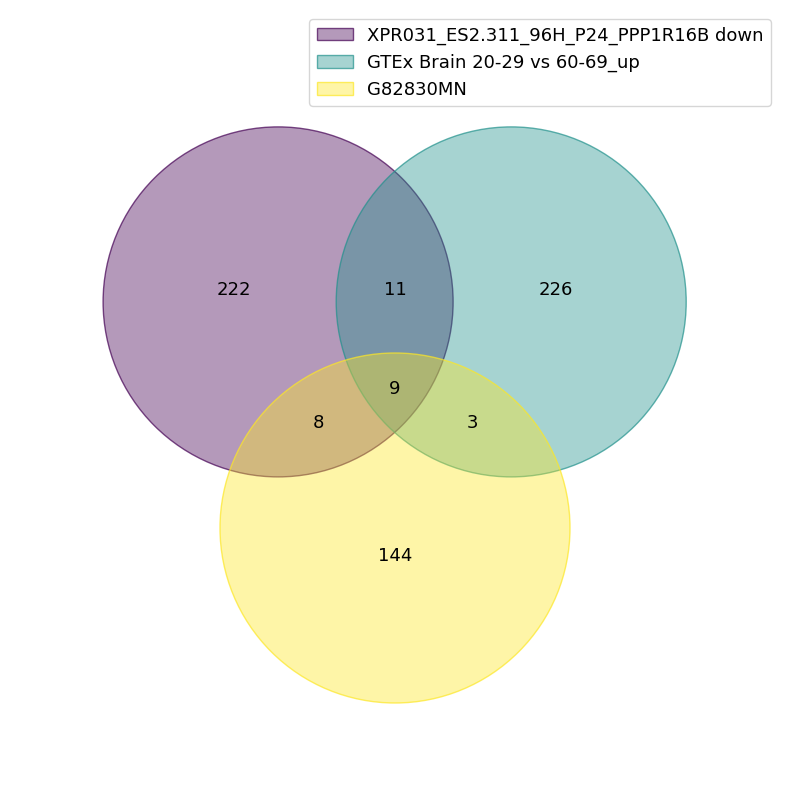

In [515]:
term_1 = crossing['Term1']
term_2 = crossing['Term2']
term_3 = crossing['Term3']

set_1 = lincscrispr[term_1]
set_2 = gtexaging[term_2]
set_3 = glygen[term_3]

plt.figure(figsize=(8,8), dpi=300)
venn({term_1:set_1, term_2:set_2, term_3:set_3})
plt.tight_layout()
#os.makedirs("report_construction/figures", exist_ok=True)
plt.savefig(f'{report_dir}/figures/venn_diagram.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [516]:
'''fig, ax = plt.subplots(figsize=(12,8), dpi=300)
venn({term_1:set_1, term_2:set_2, term_3:set_3}, cmap='viridis', fontsize=15, figsize=(12,8), legend_loc='upper left', ax=ax)
ax.legend(terms, prop={"size": 15}, loc='upper left', bbox_to_anchor=(1.0, 0.5))

plt.tight_layout()
plt.show()'''

'fig, ax = plt.subplots(figsize=(12,8), dpi=300)\nvenn({term_1:set_1, term_2:set_2, term_3:set_3}, cmap=\'viridis\', fontsize=15, figsize=(12,8), legend_loc=\'upper left\', ax=ax)\nax.legend(terms, prop={"size": 15}, loc=\'upper left\', bbox_to_anchor=(1.0, 0.5))\n\nplt.tight_layout()\nplt.show()'

### Bar Chart

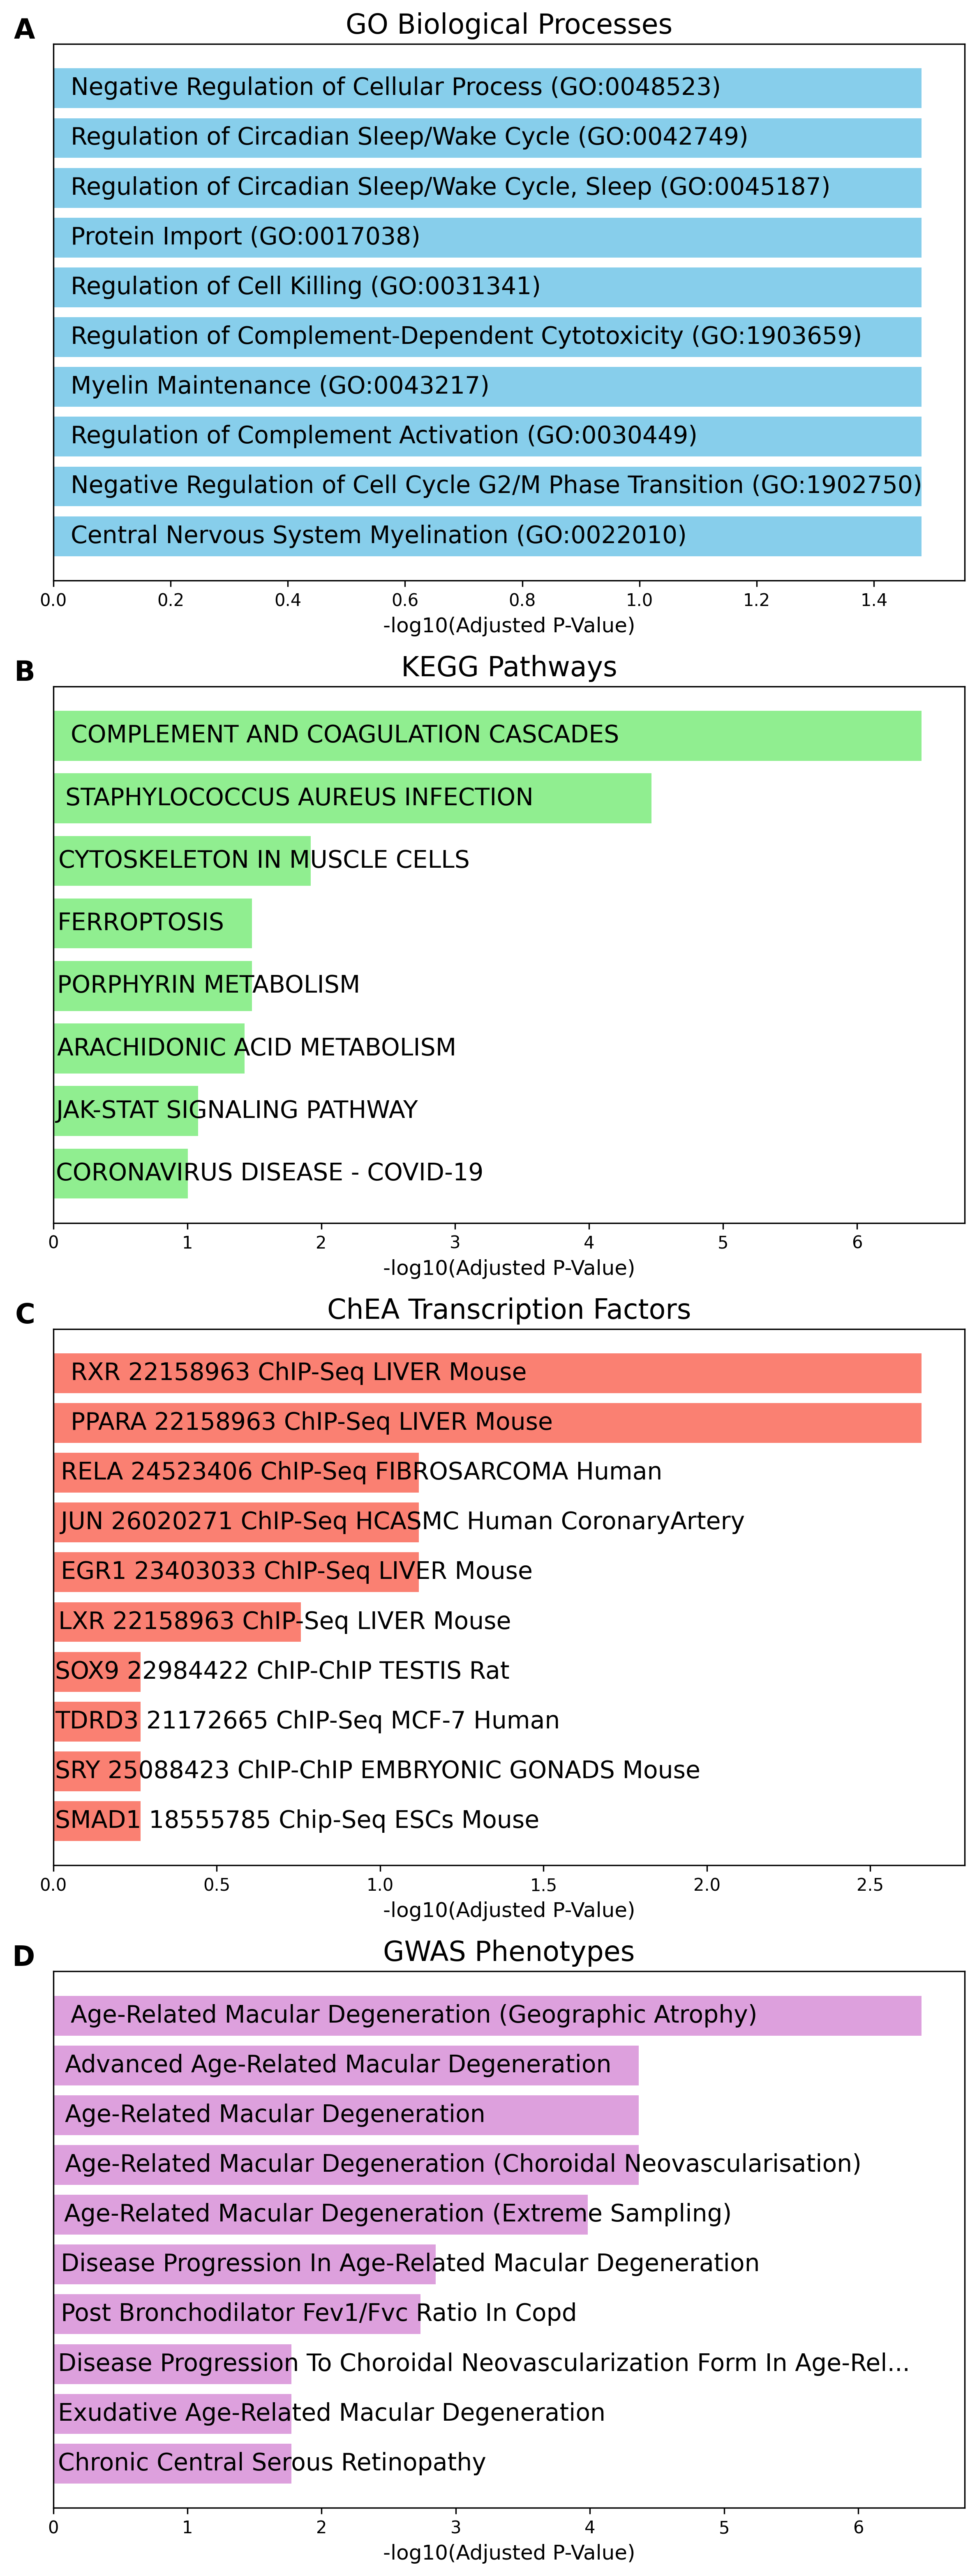

In [517]:
fig, axes = plt.subplots(4, 1, figsize=(8,21), dpi=300)

titles = ["GO Biological Processes", "KEGG Pathways", "ChEA Transcription Factors", "GWAS Phenotypes"]
colors = ["skyblue","lightgreen","salmon","plum"]
panel_labels = ["A", "B", "C", "D"]

for ax, i, title, color, label in zip(axes.flatten(), range(4), titles, colors, panel_labels):
    top = dfs[i][['Term name','Adjusted p-value']][:10][::-1]
    top['Term name'] = top['Term name'].map(truncate)
    top['-log10p'] = top['Adjusted p-value'].apply(np.log10).apply(lambda x: x*-1)

    bars = ax.barh(range(len(top)), top['-log10p'], color=color)

    # Remove y-axis ticks
    ax.set_yticks([])
    ax.set_yticklabels([])

    # Titles / labels
    ax.set_title(title, fontsize=16, fontweight='normal')
    ax.set_xlabel("-log10(Adjusted P-Value)", fontsize=12)

    # ---- Labels INSIDE bars ----
    for i, (term, z) in enumerate(zip(top['Term name'], top['-log10p'])):
        ax.text(
            z * 0.02,         # small left padding inside bar
            i,
            term,
            va='center',
            ha='left',
            fontsize=14,
            weight=525,
            color='black',
            clip_on=True
        )

    # Panel label
    ax.text(-0.02, 1.05, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(f'{report_dir}/figures/enrichment_bar.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

### Template

In [45]:
env = jinja2.Environment(
    loader=jinja2.PackageLoader('template'),
    variable_start_string='(((',
    variable_end_string=')))',
)
template = env.get_template("paper_3.tex")

genes = crossing["Genes"].split(" ")
n_genes = len(genes)

In [46]:
rendered = template.render(
    title=report_title,
    abstract=revised_abstract,
    dataset_info=dataset_info,
    introduction=revised_introduction,
    p_value=crossing["p-value"],
    jaccard=crossing["Jaccard"],
    n_genes=n_genes,
    intersecting_genes= ", and ".join(", ".join(genes).rsplit(", ",1)),
    n_sets="three",
    gene_summaries=intersection_summary,
    enrichment_results=revised_enrichment,
    discussion=revised_discussion,
    rank=1
)

In [47]:
shutil.copy("template/extras/ExcelAtFIT.cls", f"{report_dir}/")
shutil.copy("template/extras/cfde-reports-logo.png", f"{report_dir}/")

with open(f"{report_dir}/paper.tex", "w") as tmp:
    tmp.write(rendered)

### Bibliography

In [48]:
refs = {
    "CFDE":"10.1016/j.jmb.2026.169631",
    "LINCS":"10.1093/nar/gkac328", 
    "GTEx":"10.1126/science.aaz1776",
    "GlyGen":"10.1093/glycob/cwz080",
    "Enrichr":"10.1002/cpz1.90",
    "GO":"10.1093/nar/gkaf1292",
    "KEGG":"10.1093/nar/gkae909",
    "ChEA":"10.1093/nar/gkz446",
    "GWASCatalog":"10.1093/nar/gkae1070",
    "GeneSetCart":"10.1093/gigascience/giaf025",
    "Harmonizome":"10.1093/nar/gkae1080",
    "GSFM":"10.1101/2025.05.30.657124"
}

In [49]:
bib = ""
for res,ref in refs.items():
    ref = get_bibtex_from_doi(ref)
    c = ref.split(",")
    c[0] = "@misc{"+res
    bib += ",".join(c)
for reference in gene_summary_bib.values():
    bib += reference
    bib += '\n'

In [50]:
with open(f"{report_dir}/references.bib", "w") as f:
    f.write(bib)

### Construct Report

In [19]:
import subprocess
import shutil

In [30]:
report_dir="PPP1R16B_report"
construction_result = subprocess.run(["latexmk","-pdf","-cd","-lualatex",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)


Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
Latexmk: Changing directory to 'PPP1R16B_report/'
No existing .aux file, so I'll make a simple one, and require run of *latex.
Latexmk: applying rule 'lualatex'...
Rule 'lualatex':  Reasons for rerun
Category 'other':
  Rerun of 'lualatex' forced or previously required:
    Reason or flag: 'Initial setup'

------------
Run number 1 of rule 'lualatex'
------------
------------
Running 'lualatex  -recorder  "paper.tex"'
------------
This is LuaHBTeX, Version 1.21.0 (TeX Live 2025) 
 restricted system commands enabled.
(./paper.tex
LaTeX2e <2024-11-01> patch level 2
L3 programming layer <2025-01-18>
 (./ExcelAtFIT.cls
Document Class: ExcelAtFIT 25/01/2012, v1.0
(/usr/local/texlive/2025/texmf-dist/tex/latex/base/ifthen.sty)
(/usr/local/texlive/2025/texmf-dist/tex/latex/tools/calc.sty)
(/usr/local/texlive/2025/texmf-dist/tex/latex/base/article.cls
Document Class: article 2024/06/29 v1.4n Standard LaT

In [31]:
construction_result = subprocess.run(["latexmk","-cd","-c",f"{report_dir}/paper.tex"], capture_output=True, text=True)
print(construction_result.stderr)
print(construction_result.stdout)


Rc files read:
  NONE
Latexmk: This is Latexmk, John Collins, 27 Dec. 2024. Version 4.86a.
No specific requests made, so using default for latexmk.
Latexmk: Changing directory to 'PPP1R16B_report/'
Latexmk: Doing main (small) clean up for 'paper.tex'
Latexmk: Undoing directory change




In [32]:
shutil.copy(f'{report_dir}/paper.pdf', f'{report_dir}/PPP1R16B_report.pdf')

'PPP1R16B_report/PPP1R16B_report.pdf'

View [paper](PPP1R16B_report/PPP1R16B_report.pdf)

In [557]:
terms

['XPR031_ES2.311_96H_P24_PPP1R16B down',
 'GTEx Brain 20-29 vs 60-69_up',
 'G82830MN']

## Poster Figure

In [527]:
figcrossings = pd.read_csv('rummageodrug_gtexaging_motrpac_mwmetabolites.tsv', sep='\t', index_col=0)
figcrossings['Term1'] = figcrossings['Term1'].apply(clean_term)

figcrossing = figcrossings.loc[0].copy()
figcrossing["p-value"] = f'{figcrossing.loc["p-value"]:.3e}'
figcrossing["Jaccard"] = f'{figcrossing.loc["Jaccard"]:.4f}'
figcrossing = figcrossing.astype(str)
terms = list(figcrossing.loc[['Term1', 'Term2', 'Term3', 'Term4']])
gene_set = figcrossing.loc['Genes'].split(' ')
figcrossing

Term1                          GSE255432 4 v 0 imeglimin mouse up
Term1 Length                                                 1422
Term2                                GTEx Heart 20-29 vs 60-69_dn
Term2 Length                                                  249
Term3                              t69-brown-adipose_consensus_up
Term3 Length                                                 1470
Term4                                                        NAD+
Term4 Length                                                  105
p-value                                                 1.145e-13
Jaccard                                                    0.0041
Overlap                                                        11
Genes           DLAT DLD DLST IDH3B LDHB MDH1 MDH2 NDUFS1 NDUF...
Name: 0, dtype: object

In [528]:
rummageodrug = load_rummageo_gmt('cfgmts/rummageodrug.gmt')
gtexaging = load_gmt('cfgmts/gtexagingsignatures_up.gmt', '_up') | load_gmt('cfgmts/gtexagingsignatures_dn.gmt', '_dn')
motrpac = load_gmt('cfgmts/motrpac_up.gmt', '_up') | load_gmt('cfgmts/motrpac_dn.gmt', '_dn')
metabolomics = load_gmt('cfgmts/mwmetabolites_up.gmt')

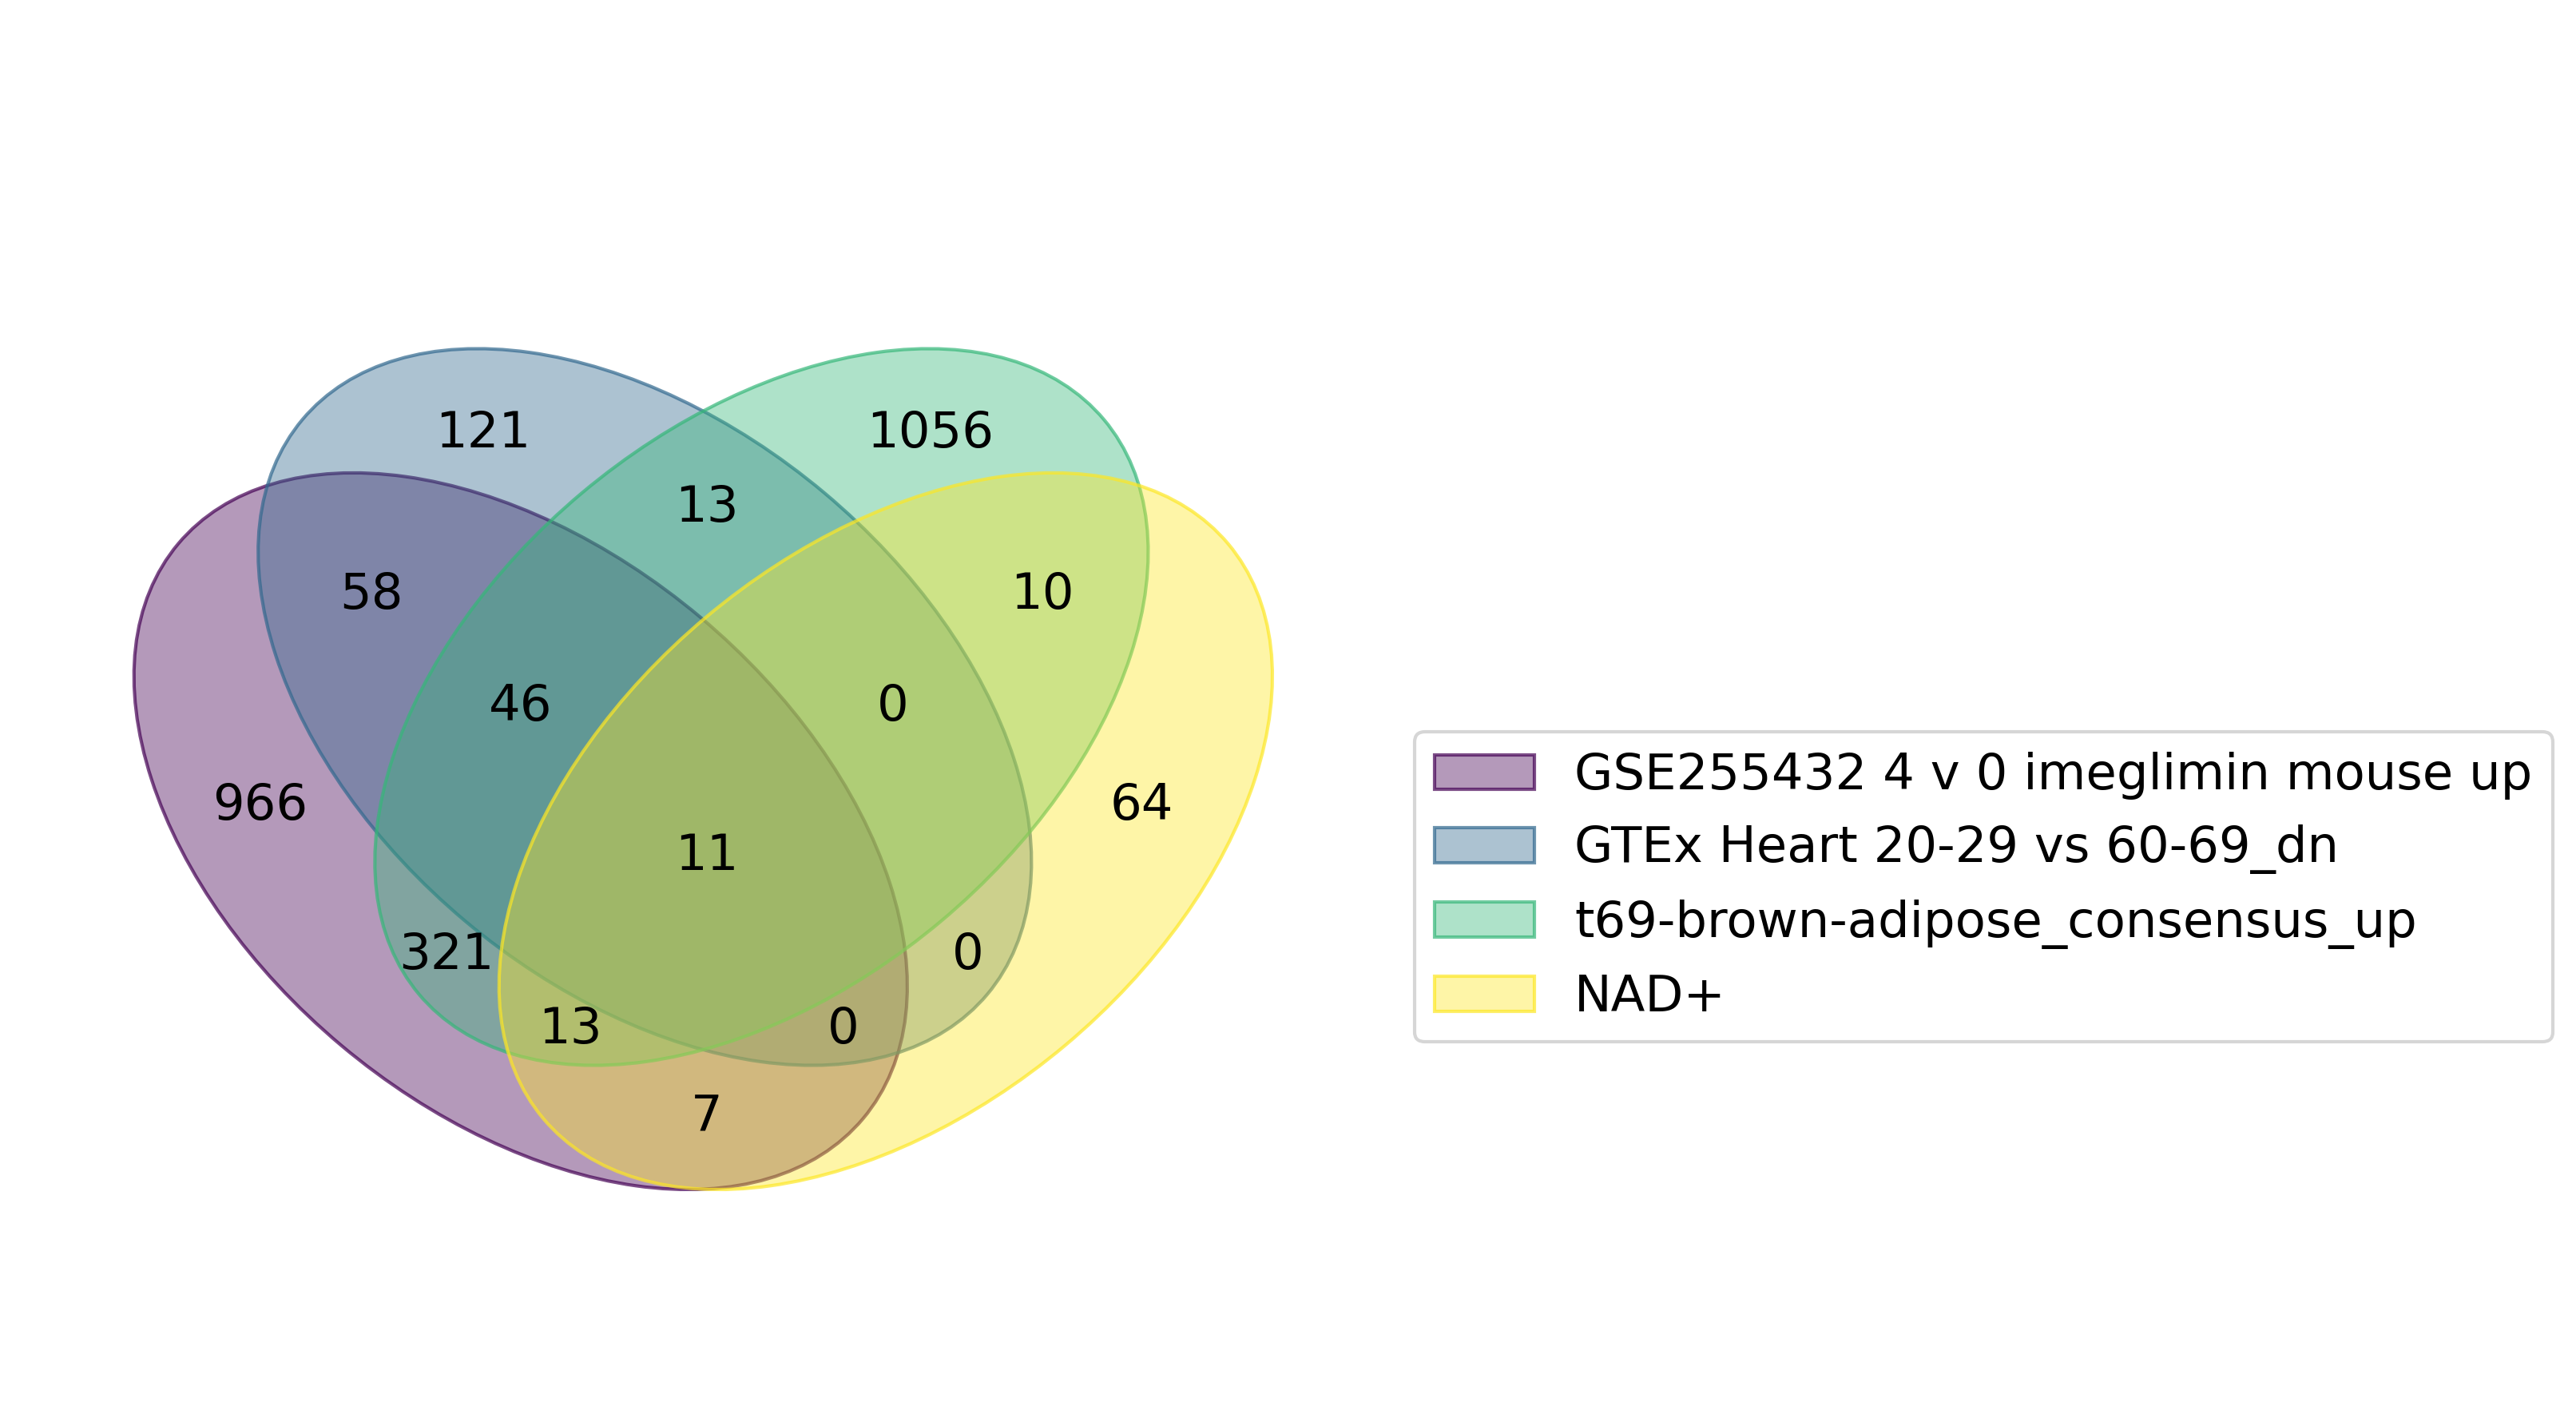

In [531]:
fig_set_1 = rummageodrug[figcrossing['Term1'].upper()]
fig_set_2 = gtexaging[figcrossing['Term2']]
fig_set_3 = motrpac[figcrossing['Term3']]
fig_set_4 = metabolomics[figcrossing['Term4']]

fig, ax = plt.subplots(figsize=(12,6), dpi=300)
venn({figcrossing['Term1']:fig_set_1, figcrossing['Term2']:fig_set_2, figcrossing['Term3']:fig_set_3, figcrossing['Term4']:fig_set_4}, cmap='viridis', fontsize=15, figsize=(12,6), legend_loc='upper left', ax=ax)
ax.legend(terms, prop={"size": 15}, loc='upper left', bbox_to_anchor=(1.0, 0.5))

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(12,8), dpi=300)
venn({term_1:set_1, term_2:set_2, term_3:set_3}, cmap='viridis', fontsize=15, figsize=(12,8), legend_loc='upper left', ax=ax)
ax.legend(terms, prop={"size": 15}, loc='upper left', bbox_to_anchor=(1.0, 0.5))

plt.tight_layout()
plt.show()

'fig, ax = plt.subplots(figsize=(12,8), dpi=300)\nvenn({term_1:set_1, term_2:set_2, term_3:set_3}, cmap=\'viridis\', fontsize=15, figsize=(12,8), legend_loc=\'upper left\', ax=ax)\nax.legend(terms, prop={"size": 15}, loc=\'upper left\', bbox_to_anchor=(1.0, 0.5))\n\nplt.tight_layout()\nplt.show()'